# Notebook 12: Stat-Arb and Many Pairs

**References:** Johansen, S. (1991). Estimation and hypothesis testing of cointegration vectors in Gaussian vector autoregressive models. *Econometrica* 59(6), 1551-1580. Chan, E. P. (2013). *Algorithmic Trading: Winning Strategies and Their Rationale*, chapter 2. Wiley. Avellaneda, M. and Lee, J.-H. (2010). Statistical arbitrage in the US equities market. *Quantitative Finance* 10(7), 761-782. Gatev, E., Goetzmann, W. N. and Rouwenhorst, K. G. (2006). Pairs trading: performance of a relative-value arbitrage rule. *Review of Financial Studies* 19(3), 797-827. Rad, H., Low, R. K. Y. and Faff, R. (2016). The profitability of pairs trading strategies: distance, cointegration and copula methods. *Quantitative Finance* 16(10), 1541-1558. Schwert, G. W. (1989). Tests for unit roots: a Monte Carlo investigation. *Journal of Business & Economic Statistics* 7(2), 147-159.

Notebooks 10 and 11 traded one relation between two books. Real relative-value trading holds many at once, and a relation can take more than two names. This notebook moves to many books with several common factors, where it can ask the questions two books cannot: how many relations there are, whether a basket beats a pair, what stat-arb on PCA residuals does for the same market, and what many pairs at once are worth.

**The model** (`lob/statarb.py`). Each book's traders place orders around its fair value, as in notebook 10. The fair values share $k$ common factors, random walks, through a table of loadings $B$, and each has a part of its own, mean-reverting and moved by order flow:

$$F_i = \ell_i + \sum_j B_{ij} X_j + U_i, \qquad dU_i = -\kappa\,U_i\,dt + \sigma_u\,dW_i + \lambda\,dQ_i.$$

Any portfolio $w$ with $w'B = 0$ leaves the factors out, so $w'F$ mean-reverts: the books have $n - \text{rank}(B)$ independent relations. So a pair is truly cointegrated only if its two rows of $B$ are parallel, and the table decides what there is to find. Two tables, twelve books each and nine relations each:

- **Sectors.** A market factor, and one factor for each of three sectors of four books. The 18 pairs within a sector are cointegrated, and the other 48 are not.
- **Mixed.** Three factors with loadings in no such order. No pair is cointegrated, and each relation takes at least four books.

As in notebook 11, comparisons are like for like: every trader alone in its market, on the same seeds, measured over the same 20,000 units of time after the same warm-up, paying what crossing the spreads actually costs in the books. Every setting except those fitted in section 10 was chosen on seeds 1 to 8, and the fitted ones on training runs of their own; everything reported here is on seeds none of them was chosen on.

In [1]:
import itertools
import math
import sys

sys.path.insert(0, '..')
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, StrMethodFormatter
from joblib import Parallel, delayed
from IPython.display import display
from quant_plots import Backtest, scorecard, signal_chart
from statsmodels.tsa.stattools import coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen

from lob.analysis.plotting import set_style
from lob.pairs import FairValues, PairMarket, PairsTrader, score_trader
from lob.statarb import (
    BookMarket,
    CopulaPortfolio,
    FactorValues,
    RelationTrader,
    ResidualTrader,
    best_baskets,
    johansen_relations,
    mixed_loadings,
    pairs_by_distance,
    pairs_by_pvalue,
    score_portfolio,
    sector_loadings,
    trace_rank,
)

set_style()
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'

SEEDS = range(101, 113)  # none of the settings below was chosen on these
FEW = range(101, 109)  # for the tables that vary one thing
EVERY = 5.0  # every trader decides this often, in units of time
FORMATION = 2_000  # the decisions' mids a trader chooses from: 10,000 units of time
BURN = FORMATION * EVERY + 400.0
SPAN = 20_000.0
SECTORS = sector_loadings(3, 4)
MIXED = mixed_loadings(12, 3, seed=3)
MARKETS = {'sectors': dict(loadings=SECTORS), 'mixed': dict(loadings=MIXED)}
SMALL = sector_loadings(2, 3)  # six books, where a table varies a setting of the market or the trader


def scored(make, settings, seed, burn=BURN, span=SPAN):
    trader = make()
    market = BookMarket(FactorValues(**settings), seed=seed, traders=(trader,))
    return score_portfolio(market, trader, burn, span)


def compare(traders, markets=MARKETS, seeds=SEEDS, burn=BURN, span=SPAN):
    # Every trader alone in every market on every seed: the same span after the same warm-up.
    def row(market_name, name, seed):
        return {
            'market': market_name,
            'trader': name,
            'seed': seed,
            **scored(traders[name], markets[market_name], seed, burn, span),
        }

    frame = pd.DataFrame(
        Parallel(n_jobs=-1)(
            delayed(row)(market_name, name, seed) for market_name in markets for name in traders for seed in seeds
        )
    )
    table = frame.groupby(['market', 'trader'], sort=False).agg(
        pnl=('pnl', 'mean'),
        se=('pnl', lambda p: p.std() / math.sqrt(len(p))),
        positive=('pnl', lambda p: f'{(p > 0).sum()} of {len(p)}'),
        before_costs=('before_costs', 'mean'),
        costs=('costs', 'mean'),
        lots=('lots', 'mean'),
        entries=('entries', 'mean'),
        gross=('gross', 'mean'),
        exposure=('exposure', 'mean'),
        risk_adjusted=('risk_adjusted', 'mean'),
    )
    table['cost_a_lot'] = table.costs / table.lots.replace(0, np.nan)
    table['pnl_a_gross_lot'] = table.pnl / table.gross.replace(0, np.nan)
    return frame, table


def shown(table, *drop):
    return (
        table.drop(columns=list(drop))
        .round(
            {
                'pnl': 0,
                'se': 0,
                'before_costs': 0,
                'costs': 0,
                'lots': 0,
                'entries': 0,
                'gross': 1,
                'exposure': 1,
                'risk_adjusted': 3,
                'cost_a_lot': 2,
                'pnl_a_gross_lot': 0,
            }
        )
        .to_string()
    )

## 1. Many Books, Several Factors

One run of each market, 4,000 units of time, with no trader in it. On the left, within a sector the books move together and across sectors they part; a pair within a sector is a mean-reverting gap, and a pair across sectors takes up the difference of two random walks. On the right the books have no such order. The pair shown is the nearest to parallel the table has, and a relation of four books leaves all three factors out exactly.

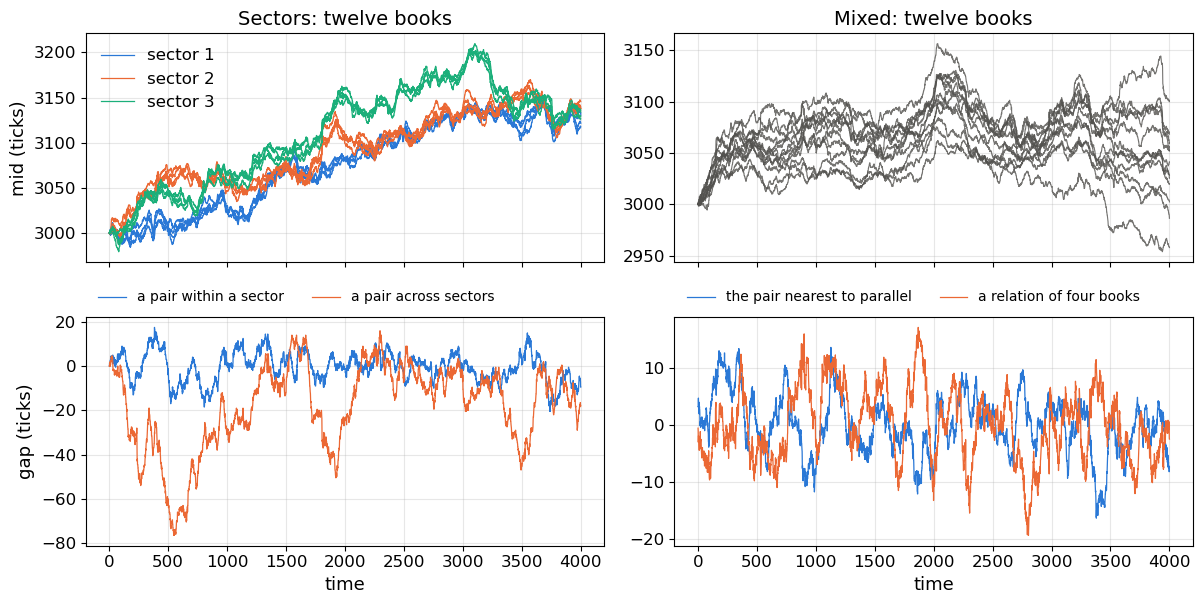

True relations: sectors 9, mixed 9.


In [2]:
def sample(loadings, seed=101, units=4_000):
    market = BookMarket(FactorValues(loadings), seed=seed)
    frame = market.run(units)
    return frame.time.to_numpy(), frame[[f'mid_{i}' for i in range(12)]].to_numpy(float)


def nearest_pair(b):
    def left(x, y):
        return np.linalg.norm(b[x] - (b[x] @ b[y]) / (b[y] @ b[y]) * b[y])

    return min(itertools.combinations(range(len(b)), 2), key=lambda p: left(*p))


def relation_on(b, books):
    row = np.zeros(len(b))
    row[list(books)] = np.linalg.svd(b[list(books)].T)[2][-1]
    return row / np.abs(row).max()


time_s, mids_s = sample(SECTORS)
time_m, mids_m = sample(MIXED)
x, y = nearest_pair(MIXED)
gamma = (MIXED[x] @ MIXED[y]) / (MIXED[y] @ MIXED[y])
basket = relation_on(MIXED, (x, y, *[i for i in range(12) if i not in (x, y)][:2]))

fig, axes = plt.subplots(2, 2, figsize=(12.5, 6.2), sharex=True)
for s, color in enumerate((BLUE, ORANGE, AQUA)):
    for i in range(4):
        axes[0, 0].plot(time_s, mids_s[:, s * 4 + i], color=color, lw=0.9, label=f'sector {s + 1}' if i == 0 else None)
axes[0, 0].set_ylabel('mid (ticks)')
axes[0, 0].set_title('Sectors: twelve books')
axes[0, 0].legend(frameon=False, loc='upper left')
axes[1, 0].plot(time_s, mids_s[:, 0] - mids_s[:, 1], color=BLUE, lw=0.9, label='a pair within a sector')
axes[1, 0].plot(time_s, mids_s[:, 0] - mids_s[:, 4], color=ORANGE, lw=0.9, label='a pair across sectors')
axes[1, 0].set_ylabel('gap (ticks)')
axes[1, 0].set_xlabel('time')
axes[1, 0].legend(frameon=False, ncol=2, loc='lower left', bbox_to_anchor=(0, 1), fontsize=10)
for i in range(12):
    axes[0, 1].plot(time_m, mids_m[:, i], color=GRAY, lw=0.8, alpha=0.8)
axes[0, 1].set_title('Mixed: twelve books')
pair = mids_m[:, x] - gamma * mids_m[:, y]
relation = mids_m @ basket
axes[1, 1].plot(time_m, pair - pair.mean(), color=BLUE, lw=0.9, label='the pair nearest to parallel')
axes[1, 1].plot(time_m, relation - relation.mean(), color=ORANGE, lw=0.9, label='a relation of four books')
axes[1, 1].set_xlabel('time')
axes[1, 1].legend(frameon=False, ncol=2, loc='lower left', bbox_to_anchor=(0, 1), fontsize=10)
fig.tight_layout()
plt.show()
print(f'True relations: sectors {FactorValues(SECTORS).rank}, mixed {FactorValues(MIXED).rank}.')

## 2. What the Tests See

Before trading any of it: how much of this can be found from the mids alone? The Johansen trace test gives the number of relations. Engle-Granger, run on every pair, says which pairs are cointegrated. Twelve runs of each market, the tests on the first part of each.

In [3]:
RANK_SPANS = (2_000, 5_000, 10_000, 20_000)


def leftover(b, x, y):
    return float(np.linalg.norm(b[x] - (b[x] @ b[y]) / (b[y] @ b[y]) * b[y]))


def what_the_tests_see(name, seed):
    loadings = MARKETS[name]['loadings']
    frame = BookMarket(FactorValues(loadings), seed=seed).run(20_000)
    mids = frame[[f'mid_{i}' for i in range(12)]].dropna().to_numpy(float)[::5]
    ranks = {units: trace_rank(coint_johansen(mids[: units // 5], det_order=0, k_ar_diff=2)) for units in RANK_SPANS}
    flags = [
        {
            'market': name,
            'seed': seed,
            'left': leftover(loadings, x, y),
            'flagged': coint(mids[:, x], mids[:, y], maxlag=20, autolag='AIC')[1] < 0.05,
        }
        for x, y in itertools.combinations(range(12), 2)
    ]
    return {'market': name, 'seed': seed, **{f'rank over {u:,}': r for u, r in ranks.items()}}, flags


seen = Parallel(n_jobs=-1)(delayed(what_the_tests_see)(name, seed) for name in MARKETS for seed in SEEDS)
ranks = pd.DataFrame([row for row, _ in seen])
flags = pd.DataFrame([flag for _, some in seen for flag in some])
rank_table = ranks.drop(columns='seed').groupby('market', sort=False).agg(['mean', 'min', 'max']).round(1)
print('Johansen: the relations found, of 9 true ones')
print(rank_table.to_string())
print()
flags['factors left in the pair'] = pd.cut(
    flags.left, [-1, 0.001, 0.3, 0.7, 2.0], labels=['none: truly cointegrated', 'under 0.3', '0.3 to 0.7', 'over 0.7']
)
flagged = flags.groupby(['market', 'factors left in the pair'], observed=True, sort=False).agg(
    pairs=('flagged', lambda f: len(f) // len(SEEDS)), called_cointegrated=('flagged', 'mean')
)
flagged['called_cointegrated'] = (100 * flagged.called_cointegrated).round(0)
print('Engle-Granger at 5% over 20,000 units: the share of pairs it calls cointegrated, in %')
print(flagged.to_string())
across = flags[(flags.market == 'sectors') & (flags.left > 0.001)].groupby('seed').flagged.sum()
print(
    f'\nCross-sector pairs called cointegrated in a run: {across.mean():.1f} on average, and in '
    f'{(across > 0).sum()} of {len(across)} runs; when any are, {across[across > 0].mean():.1f} on average, of 48.'
)

Johansen: the relations found, of 9 true ones
        rank over 2,000         rank over 5,000         rank over 10,000         rank over 20,000        
                   mean min max            mean min max             mean min max             mean min max
market                                                                                                   
sectors             0.3   0   1             6.2   3   9              9.0   9   9              9.2   9  10
mixed               0.2   0   1             6.7   5   9              9.0   9   9              9.0   9   9

Engle-Granger at 5% over 20,000 units: the share of pairs it calls cointegrated, in %
                                  pairs  called_cointegrated
market  factors left in the pair                            
sectors none: truly cointegrated     18                100.0
        over 0.7                     48                 10.0
mixed   over 0.7                     23                  8.0
        0.3 to 0.7              

**Johansen needs a long past.** Over 2,000 units of time, 40 half-lives, it finds almost none of the nine relations; over 5,000, about two thirds; over 10,000, all nine in every run. That is why the traders here choose from 10,000 units.

**Engle-Granger cannot tell a cointegrated pair from one that nearly is.** "Factors left in the pair" is how much of its first book's loadings the best hedge with the second leaves over. In the mixed market no pair has none, yet the test calls 91% of those with under 0.3 left cointegrated, and 46% of those with 0.3 to 0.7. Over this span the random walk left in such a pair is small beside its own parts' swings, and a unit-root test is known to reject far too often in that case (Schwert 1989). Whether that is a fault for a trader is the question for section 4.

**Even unrelated pairs pass too often, and they come in bunches.** Pairs with over 0.7 left are called cointegrated 8 to 10% of the time, at a nominal 5%. Across sectors that does not mean about two in each run: in most runs there are none, and in 4 of the 12 about 14 of the 48 at once, because when two sector factors happen to keep together, so do all the pairs across them. Anyone choosing many pairs by this test takes on that risk together.

## 3. Does a Shared Seed Help?

Notebook 11 found that two traders on one seed share a market only until the first trade, so comparing them by seed takes out little of the luck. In `lob/statarb.py` the factors and the shocks to the own parts have a random stream of their own, on a grid of time, so that a seed gives the same paths whatever trades. Does that sharpen a comparison? The fair test is one relation under different settings, since traders on different relations have different luck anyway.

In [4]:
SAME_RELATION = {
    'window 400, entry 1.5': dict(window=400, entry=1.5),
    'window 400, entry 2': dict(window=400, entry=2.0),
    'window 400, entry 2.5': dict(window=400, entry=2.5),
    'window 1,000, entry 2': dict(window=1000, entry=2.0),
    'window 2,000, entry 2': dict(window=2000, entry=2.0),
}


def on_old_market(name, seed):
    trader = PairsTrader(**SAME_RELATION[name])
    market = PairMarket(FairValues(level_a=3000.0, level_b=3000.0, volatility=1.0), seed=seed, traders=(trader,))
    return {
        'market': 'lob/pairs.py, two books',
        'setting': name,
        'seed': seed,
        **score_trader(market, trader, 2001.0, 10_000.0),
    }


def on_new_market(name, seed, books):
    weights = np.zeros(books)
    weights[0], weights[1] = 1.0, -1.0
    trader = RelationTrader(weights=weights[None, :], **SAME_RELATION[name])
    market = BookMarket(FactorValues(sector_loadings(1, books)), seed=seed, traders=(trader,))
    return {
        'market': f'lob/statarb.py, {books} books',
        'setting': name,
        'seed': seed,
        **score_portfolio(market, trader, 2001.0, 10_000.0),
    }


runs = Parallel(n_jobs=-1)(
    [delayed(on_old_market)(name, seed) for name in SAME_RELATION for seed in SEEDS]
    + [delayed(on_new_market)(name, seed, books) for books in (2, 6) for name in SAME_RELATION for seed in SEEDS]
)
same = pd.DataFrame(runs)
rows = {}
for market, group in same.groupby('market', sort=False):
    wide = group.pivot(index='seed', columns='setting', values='pnl')
    together = np.corrcoef(wide.to_numpy().T)
    apart = [
        (wide[a] - wide[b]).std() / math.sqrt(wide[a].var() + wide[b].var())
        for a, b in itertools.combinations(wide.columns, 2)
    ]
    rows[market] = {
        'mean correlation across seeds': together[np.triu_indices_from(together, 1)].mean(),
        'sd of a difference, against unpaired': np.mean(apart),
        **{name: wide[name].mean() for name in SAME_RELATION},
    }
seed_table = pd.DataFrame(rows).T
print(
    seed_table.round(
        {
            'mean correlation across seeds': 2,
            'sd of a difference, against unpaired': 2,
            **{name: 0 for name in SAME_RELATION},
        }
    ).T.to_string()
)

                                      lob/pairs.py, two books  lob/statarb.py, 2 books  lob/statarb.py, 6 books
mean correlation across seeds                           -0.03                     0.41                     0.32
sd of a difference, against unpaired                     1.01                     0.76                     0.82
window 400, entry 1.5                                  112.00                    34.00                   -10.00
window 400, entry 2                                    287.00                   301.00                   350.00
window 400, entry 2.5                                  296.00                   351.00                   362.00
window 1,000, entry 2                                  626.00                   655.00                   609.00
window 2,000, entry 2                                  628.00                   695.00                   716.00


**It helps, modestly.** On the market of notebooks 10 and 11 the correlation across seeds is about zero, and a difference between two settings is as noisy as if the seeds had been different. With a stream of their own the correlation is 0.3 to 0.4, and the difference's standard deviation falls to about 0.8 of that, which is worth about one and a half times as many runs, or a little more. It is no more because order flow still differs from the first trade on: its random numbers have a stream of their own, but how many it takes depends on the books. Different windows and entry levels also trade at different moments on the same paths.

The last rows are a check on the new market itself: the same trader earns the same in it as in `lob/pairs.py`, within the noise.

## 4. One Table

Every kind of trader in both markets. Each has settings from a small grid looked at on seeds 1 to 8, and the z-score traders have the long window that notebook 11's fits found, with its entry of 2; section 10 instead fits them on training runs of their own, the way the dashboard's panel does. Sizes are the lots of a relation's largest leg, small enough not to walk the book much. The two rows of residuals are Avellaneda and Lee's published rule, with their levels of 1.25, 0.5 and 0.75 and a window of 120 decisions, about eight mean-reversion times here (theirs is 60 days, in which they accept any stock with at least two), and the same trader with the longer window and later entry and exit that did best here.

                                         pnl     se  positive  before_costs    costs     lots  entries  gross  exposure  risk_adjusted  cost_a_lot  pnl_a_gross_lot
market  trader                                                                                                                                                     
sectors pairs by distance, 8          5701.0   77.0  12 of 12        8525.0   2824.0   2386.0    273.0    8.3       0.9          0.070        1.18            688.0
        pairs by p-value, 8           5698.0   90.0  12 of 12        8595.0   2896.0   2420.0    277.0    8.4       0.9          0.070        1.20            682.0
        copula pairs, 8               1913.0  111.0  12 of 12        3868.0   1955.0   1738.0    200.0   15.9       1.2          0.016        1.12            120.0
        baskets of 4 books, 4         4924.0  114.0  12 of 12        9486.0   4562.0   3332.0    137.0   12.0       0.6          0.038        1.37            409.0
        Johansen

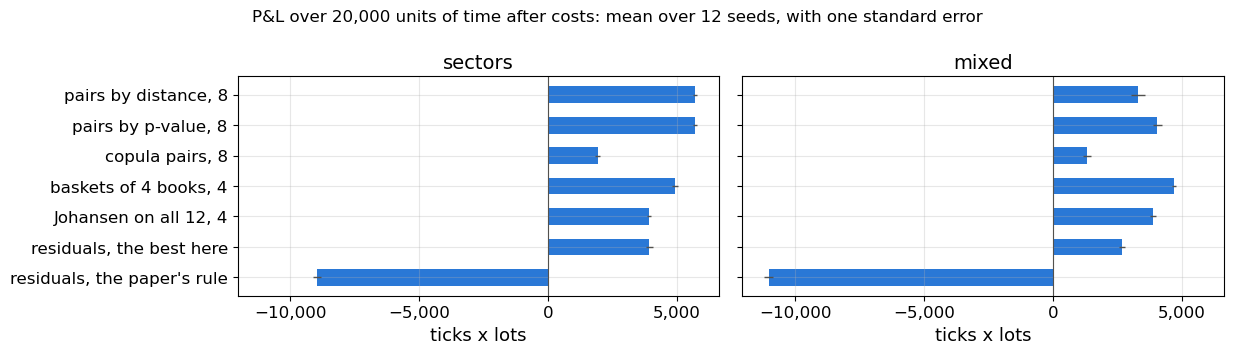

In [5]:
RESIDUAL_BEST = dict(window=400, open_at=1.5, close_long=0.0, close_short=0.0)
Z = dict(window=400, entry=2.0, interval=EVERY, formation=FORMATION)  # a window of 2,000 units of time
COPULA = dict(window=FORMATION, trading=200, entry=1.0, interval=EVERY)
BEST_RULE, PAPER_RULE = 'residuals, the best here', "residuals, the paper's rule"
KINDS = {
    'pairs by distance, 8': lambda: RelationTrader(choose=partial(pairs_by_distance, count=8), size=2.5, **Z),
    'pairs by p-value, 8': lambda: RelationTrader(choose=partial(pairs_by_pvalue, count=8, every=1), size=2.5, **Z),
    'copula pairs, 8': lambda: CopulaPortfolio(pairs=8, size=2.5, **COPULA),
    'baskets of 4 books, 4': lambda: RelationTrader(
        choose=partial(best_baskets, count=4, legs=4, every=1), size=5.0, **Z
    ),
    'Johansen on all 12, 4': lambda: RelationTrader(
        choose=partial(johansen_relations, count=4, every=1), size=5.0, **Z
    ),
    BEST_RULE: lambda: ResidualTrader(factors=3, interval=EVERY, size=5.0, **RESIDUAL_BEST),
    PAPER_RULE: lambda: ResidualTrader(factors=3, interval=EVERY, size=5.0),
}
kinds_frame, kinds = compare(KINDS)
print(shown(kinds))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6), sharex=True, sharey=True)
for ax, name in zip(axes, MARKETS, strict=True):
    rows = kinds.loc[name]
    place = np.arange(len(rows))[::-1]
    ax.barh(place, rows.pnl, xerr=rows.se, height=0.55, color=BLUE, error_kw=dict(ecolor=GRAY, lw=1))
    ax.axvline(0, color=GRAY, lw=0.8)
    ax.set_yticks(place, rows.index)
    ax.set_title(name)
    ax.set_xlabel('ticks x lots')
    ax.xaxis.set_major_locator(MultipleLocator(5_000))
    ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
fig.suptitle(f'P&L over {SPAN:,.0f} units of time after costs: mean over 12 seeds, with one standard error',
             fontsize=12)
fig.tight_layout()
plt.show()

**Where pairs exist, many pairs lead.** In the sectors market eight pairs make the most and, per unit of risk, about twice what anything else does. Both ways of choosing find the same pairs.

**Where no pair is truly cointegrated, pairs still pay.** This is what section 2's verdict comes to. A pair with little of the factors left in it trades like a relation over these spans, and the test's false positives are largely the right pairs to trade. In the mixed market, choosing by p-value makes +4,057 with the best figure per unit of risk there. Choosing by distance makes less, as it favors books that move about one for one, and it holds more of the factors (2.9 against 1.6).

**Baskets of four books are level with them there, and behind in sectors.** In the mixed market they make the most, at +4,695, and hold the least of the factors (0.7), but less per unit of risk than the pairs by p-value (0.044 against 0.057). What being truly cointegrated buys is less exposure to the factors, not clearly more money after costs. In the sectors market, a basket is a sum of pairs that costs more to trade.

**Johansen on all twelve books earns the most before costs, and pays the most for it.** About +12,000 before costs and about 8,000 of costs in both markets. The next section says why.

**The residuals are behind, with the settings that suit this market.** The published rule loses heavily in both markets: it earns about what the best settings earn before costs, and enters more than three times as often. Section 6 asks why.

**Copula pairs come last among those that make money,** at a third of what the z-score pairs make on the same choice of pairs in the sectors market, and with the most held for what they earn: 120 a gross lot against 688. That is notebook 11's result again, and the order Rad et al. (2016) find in US stocks, whose copula method earned least after costs.

## 5. What a Leg Costs

Why do baskets of many books do so badly after costs? Take a market with one factor, where any portfolio whose weights add up to zero is a relation, and trade portfolios of $L$ legs with weights of $\pm 1$. The own parts are independent, so the spread's swings grow as $\sqrt{L}$. What crossing costs grows as $L$. So what each round trip earns against what it costs falls as $1/\sqrt{L}$.

In [6]:
ONE_FACTOR = {'one factor': dict(loadings=np.ones((12, 1)))}


def alternating(legs):
    row = np.zeros(12)
    row[:legs] = [1.0 if i % 2 == 0 else -1.0 for i in range(legs)]
    return row[None, :]


LEGS = (2, 4, 6, 8, 12)
leg_traders = {
    f'{legs} legs': (lambda legs=legs: RelationTrader(weights=alternating(legs), window=400, interval=EVERY, size=5.0))
    for legs in LEGS
}
_, legs_table = compare(leg_traders, ONE_FACTOR, FEW, burn=2_001.0, span=15_000.0)
legs_table = legs_table.loc['one factor']
base = legs_table.iloc[0]
legs_table = legs_table.assign(
    before_costs_vs_2=legs_table.before_costs / base.before_costs,
    root_law=[math.sqrt(legs / 2) for legs in LEGS],
    costs_vs_2=legs_table.costs / base.costs,
    line_law=[legs / 2 for legs in LEGS],
)
print(
    legs_table[
        [
            'pnl',
            'se',
            'before_costs',
            'costs',
            'cost_a_lot',
            'entries',
            'risk_adjusted',
            'before_costs_vs_2',
            'root_law',
            'costs_vs_2',
            'line_law',
        ]
    ]
    .round(
        {
            'pnl': 0,
            'se': 0,
            'before_costs': 0,
            'costs': 0,
            'cost_a_lot': 2,
            'entries': 0,
            'risk_adjusted': 3,
            'before_costs_vs_2': 2,
            'root_law': 2,
            'costs_vs_2': 2,
            'line_law': 2,
        }
    )
    .to_string()
)

            pnl    se  before_costs   costs  cost_a_lot  entries  risk_adjusted  before_costs_vs_2  root_law  costs_vs_2  line_law
trader                                                                                                                            
2 legs   1011.0  41.0        1609.0   598.0        1.22     25.0          0.029               1.00      1.00        1.00       1.0
4 legs   1037.0  78.0        2311.0  1274.0        1.28     25.0          0.020               1.44      1.41        2.13       2.0
6 legs   1028.0  65.0        2891.0  1863.0        1.23     25.0          0.015               1.80      1.73        3.11       3.0
8 legs    847.0  34.0        3171.0  2324.0        1.23     24.0          0.011               1.97      2.00        3.88       4.0
12 legs   394.0  46.0        4344.0  3950.0        1.22     27.0          0.004               2.70      2.45        6.60       6.0


**The two laws hold.** From 2 legs to 12 the before-cost P&L grows 2.70 times, against 2.45 for the square root, and the costs 6.60 times, against 6. So after costs a basket gains nothing from more legs: flat up to six, and falling beyond. Per unit of risk it falls all the way, from 0.029 to 0.004, since the P&L's swings grow with the legs as well. With equal weights, then, more legs never help. That is the cost of Johansen's vectors on all the books, and why four books do better than twelve.

## 6. What the Residual Rule Needs

The published levels lose heavily here. Is that the rule, or this market? Avellaneda and Lee assume a round trip of 10 basis points against residuals with a standard deviation of about 300 basis points, a thirtieth. Here a round trip costs about 2.3 ticks a lot against about 4 ticks of residual, more than half: some 17 times as much. So widen the swings, leaving the books as they are. On six books, one pair beside the published rule, the published levels with a longer window, and the best here, as the own parts' volatility grows.

And how many factors should it take? The market has two here. Too many hedge away some of what it trades; too few leave a factor in.

In [7]:
SWINGS = {f'own volatility {own}': dict(loadings=SMALL, own_volatility=own) for own in (0.8, 1.6, 3.2)}
swing_traders = {
    'a pair': lambda: RelationTrader(choose=partial(pairs_by_distance, count=1), size=5.0, **Z),
    BEST_RULE: lambda: ResidualTrader(factors=2, interval=EVERY, **RESIDUAL_BEST),
    "the paper's levels, a long window": lambda: ResidualTrader(
        factors=2, interval=EVERY, window=RESIDUAL_BEST['window']
    ),
    PAPER_RULE: lambda: ResidualTrader(factors=2, interval=EVERY),
}
_, swings = compare(swing_traders, SWINGS, FEW)
print(shown(swings, 'lots', 'gross', 'pnl_a_gross_lot'))
print()
factor_traders = {
    f'{k} factor{"" if k == 1 else "s"}': (lambda k=k: ResidualTrader(factors=k, interval=EVERY, **RESIDUAL_BEST))
    for k in (1, 2, 3, 4)
}
_, factor_counts = compare(factor_traders, {'six books, two factors': dict(loadings=SMALL)}, FEW)
print(shown(factor_counts, 'lots', 'cost_a_lot', 'pnl_a_gross_lot'))

                                                          pnl     se positive  before_costs    costs  entries  exposure  risk_adjusted  cost_a_lot
market             trader                                                                                                                         
own volatility 0.8 a pair                              1475.0   72.0   8 of 8        2516.0   1042.0     36.0       0.0          0.025        1.44
                   residuals, the best here            1988.0   80.0   8 of 8        4228.0   2241.0    145.0       1.0          0.025        1.13
                   the paper's levels, a long window   -126.0  121.0   3 of 8        4521.0   4647.0    302.0       1.0         -0.002        1.14
                   residuals, the paper's rule        -3387.0  148.0   0 of 8        4055.0   7442.0    484.0       1.5         -0.035        1.15
own volatility 1.6 a pair                              3040.0  147.0   8 of 8        4037.0    998.0     31.0       0.

                                     pnl     se positive  before_costs   costs  entries  gross  exposure  risk_adjusted
market                 trader                                                                                          
six books, two factors 1 factor   -886.0  523.0   3 of 8        1072.0  1958.0    105.0   12.6      11.8         -0.006
                       2 factors  1988.0   80.0   8 of 8        4228.0  2241.0    145.0    6.9       1.0          0.025
                       3 factors  1478.0   84.0   8 of 8        3778.0  2299.0    160.0    7.3       1.0          0.018
                       4 factors   927.0   66.0   8 of 8        2834.0  1908.0    160.0    6.3       0.9          0.012


**The published rule does not pay here, even at four times the swings.** With its window of about eight mean-reversion times and its levels it loses at the swings of the other sections, and at four times those it only breaks even: a round trip there still costs about a quarter of a residual's standard deviation, against their thirtieth.

**The window matters most, and then the levels.** The published levels on a longer window lose about nothing at these swings (-126, se 121), and pay from twice those on. The later entry and the exit at the mean do the rest, entering about half as often and holding to the mean, to make +1,988.

**With settings that suit the costs, residuals beat one pair.** They make more at every width of swing, with as good a figure per unit of risk or better, because they hold many relations for the pair's one. Against many pairs, as section 4 shows, they do not.

**Too few factors is far worse than too many.** The market has two. One factor leaves the other in what it holds (11.8 of it, against about 1), and it makes nothing for that risk (-886, se 523). A factor too many costs about a quarter of the P&L and two about half, by hedging away some of what it trades. Choosing the number by a share of the variance, as they also do, is not tried here, where the true number is known.

## 7. Many at Once

The same 20 lots, in one relation or spread over many: does breadth pay? Before costs, a position's expected gain does not depend on how it is split. What does depend on it is how far each order walks the book.

In [8]:
TOTAL = 20.0
breadth_traders = {
    f'{m} pair{"" if m == 1 else "s"} of {TOTAL / m:g} lots': (
        lambda m=m: RelationTrader(choose=partial(pairs_by_distance, count=m), size=TOTAL / m, **Z)
    )
    for m in (1, 2, 4, 8)
}
breadth_frame, breadth = compare(breadth_traders, seeds=FEW)
breadth['sd_a_unit'] = breadth_frame.groupby(['market', 'trader'], sort=False).deviation.mean()
print(shown(breadth.assign(sd_a_unit=breadth.sd_a_unit.round(1)), 'pnl_a_gross_lot', 'lots'))
print()
netting_traders = {
    f'decides every {i} unit{"" if i == 1 else "s"}': (
        lambda i=i: RelationTrader(
            choose=partial(pairs_by_distance, count=8),
            size=5.0,
            formation=10_000 // i,
            window=2_000 // i,
            entry=Z['entry'],
            interval=float(i),
        )
    )
    for i in (1, 5, 20)
}
netting_frame, _ = compare(netting_traders, {'sectors': MARKETS['sectors']}, FEW)
netting = netting_frame.groupby('trader', sort=False).agg(
    lots=('lots', 'mean'), netted=('netted', 'mean'), pnl=('pnl', 'mean')
)
netting['saved'] = netting.netted / (netting.lots + netting.netted)
print('What netting saved: 8 pairs of 5 lots, sectors')
print(netting.round({'lots': 0, 'netted': 0, 'pnl': 0, 'saved': 4}).to_string())

                                pnl     se positive  before_costs   costs  entries  gross  exposure  risk_adjusted  cost_a_lot  sd_a_unit
market  trader                                                                                                                           
sectors 1 pair of 20 lots    2251.0  136.0   8 of 8       10394.0  8143.0     38.0   10.2       0.0          0.009        2.69       12.7
        2 pairs of 10 lots   4644.0  242.0   8 of 8       10199.0  5555.0     72.0    9.8       0.0          0.027        1.92        8.6
        4 pairs of 5 lots    5678.0  120.0   8 of 8        9826.0  4148.0    140.0   10.1       0.0          0.046        1.48        6.2
        8 pairs of 2.5 lots  5699.0  112.0   8 of 8        8540.0  2842.0    273.0    8.2       0.9          0.069        1.19        4.1
mixed   1 pair of 20 lots    2317.0  203.0   8 of 8        6714.0  4397.0     27.0   13.3       3.1          0.011        2.22       11.2
        2 pairs of 10 lots   3336.

What netting saved: 8 pairs of 5 lots, sectors
                          lots  netted      pnl   saved
trader                                                 
decides every 1 unit    7069.0     2.0  11241.0  0.0004
decides every 5 units   5532.0     7.0  11289.0  0.0013
decides every 20 units  3924.0    13.0  10176.0  0.0032


**Breadth pays twice.** First in costs: the same 20 lots cost 2.69 ticks a lot in one pair, as its orders walk the book, and 1.19 in eight, for about a third of the total costs, while the before-cost P&L falls by much less, some of that from taking in lesser pairs and from lots rounded to whole numbers. Then in risk: the P&L's standard deviation a unit of time falls from 12.7 to 4.1, by about the square root of eight, so what it makes per unit of risk rises nearly eightfold in the sectors market and nearly fourfold in the mixed one, where the pairs hold more of the factors in common.

**Netting orders saves almost nothing.** Eight pairs of 5 lots save 0.04% of their lots by sending one order a book, and 0.3% even deciding only every 20 units, because relations seldom change at the same decision. What nets is what they hold, not what they trade. This is a result for traders that decide often and one relation at a time. One that rebalanced a thousand names once a day could net far more.

## 8. When the Relations Move

So far the loadings have stayed put, which flatters anything that fixes its weights. Let every loading drift, around its start with a half-life of 2,000 units of time, and no fixed relation stays one. Choosing pairs again every 2,000 units from the last 4,000 is the obvious answer; the residual trader re-estimates all the time.

In [9]:
DRIFTS = {
    f'loadings drift by {sd}' if sd else 'loadings fixed': dict(loadings=SMALL, loading_sd=sd, loading_half_life=2000.0)
    for sd in (0.0, 0.2, 0.4)
}
drift_traders = {
    'pairs, 2': lambda: RelationTrader(choose=partial(pairs_by_distance, count=2), size=5.0, **Z),
    'pairs, 2, chosen again': lambda: RelationTrader(
        choose=partial(pairs_by_distance, count=2), size=5.0, refit=400, **{**Z, 'formation': 800}
    ),
    'baskets of 3 books, 2': lambda: RelationTrader(choose=partial(best_baskets, count=2, every=1), size=5.0, **Z),
    'copula pairs, 2': lambda: CopulaPortfolio(pairs=2, **COPULA),
    'residuals': lambda: ResidualTrader(factors=2, interval=EVERY, **RESIDUAL_BEST),
}
drift_frame, drifts = compare(drift_traders, DRIFTS, SEEDS)
print(shown(drifts, 'lots', 'cost_a_lot', 'pnl_a_gross_lot'))
wide = drift_frame[drift_frame.market == 'loadings drift by 0.4'].pivot(index='seed', columns='trader', values='pnl')
difference = wide['residuals'] - wide['pairs, 2']
print(
    f"\nWith loadings drifting by 0.4, residuals less pairs: {difference.mean():+.0f} a run "
    f"(se {difference.std() / math.sqrt(len(difference)):.0f}, {(difference > 0).sum()} of {len(difference)} above 0)"
)

                                                 pnl     se  positive  before_costs   costs  entries  gross  exposure  risk_adjusted
market                trader                                                                                                        
loadings fixed        pairs, 2                2901.0   91.0  12 of 12        4966.0  2065.0     70.0    5.0       0.0          0.034
                      pairs, 2, chosen again  3054.0   80.0  12 of 12        5147.0  2093.0     76.0    5.4       0.3          0.036
                      baskets of 3 books, 2   2604.0   91.0  12 of 12        4463.0  1858.0     68.0    5.0       0.1          0.035
                      copula pairs, 2          751.0  134.0  11 of 12        2001.0  1251.0     48.0    9.8       0.0          0.007
                      residuals               1955.0   62.0  12 of 12        4198.0  2243.0    145.0    6.8       1.0          0.024
loadings drift by 0.2 pairs, 2                1468.0  127.0  12 of 12

**Every trader fades as the loadings drift, and by 0.4 little is left.** Their exposure to the factors grows as hedges go stale, from about nothing to about 5 or 6, and with it their risk. Pairs fall from +2,901 to +199 (se 315), and copula pairs and baskets end about flat.

**Choosing pairs again does not help,** at either level of drift.

**The residuals keep their edge before costs, not after.** They re-estimate at each decision, and before costs they make +2,818 at the highest drift against +964 for pairs. But they pay most of it away, and after costs the difference is +305 (se 344, in 5 of 12 runs): not clear. So re-estimating does find something when the relations move, and these costs take it. Whether a slower rule would keep it is not tested here.

## 9. In a Backtest's Terms

The scorecard and signal chart of each kind, on a seed that played no part in choosing its settings. As in notebooks 10 and 11, the record has one row per decision: what the trader held after it, valued at the mids just before its orders, with costs that add up to what crossing the spreads cost. The signal chart shows one book, one of many it holds, with the signal of a relation that book is in.

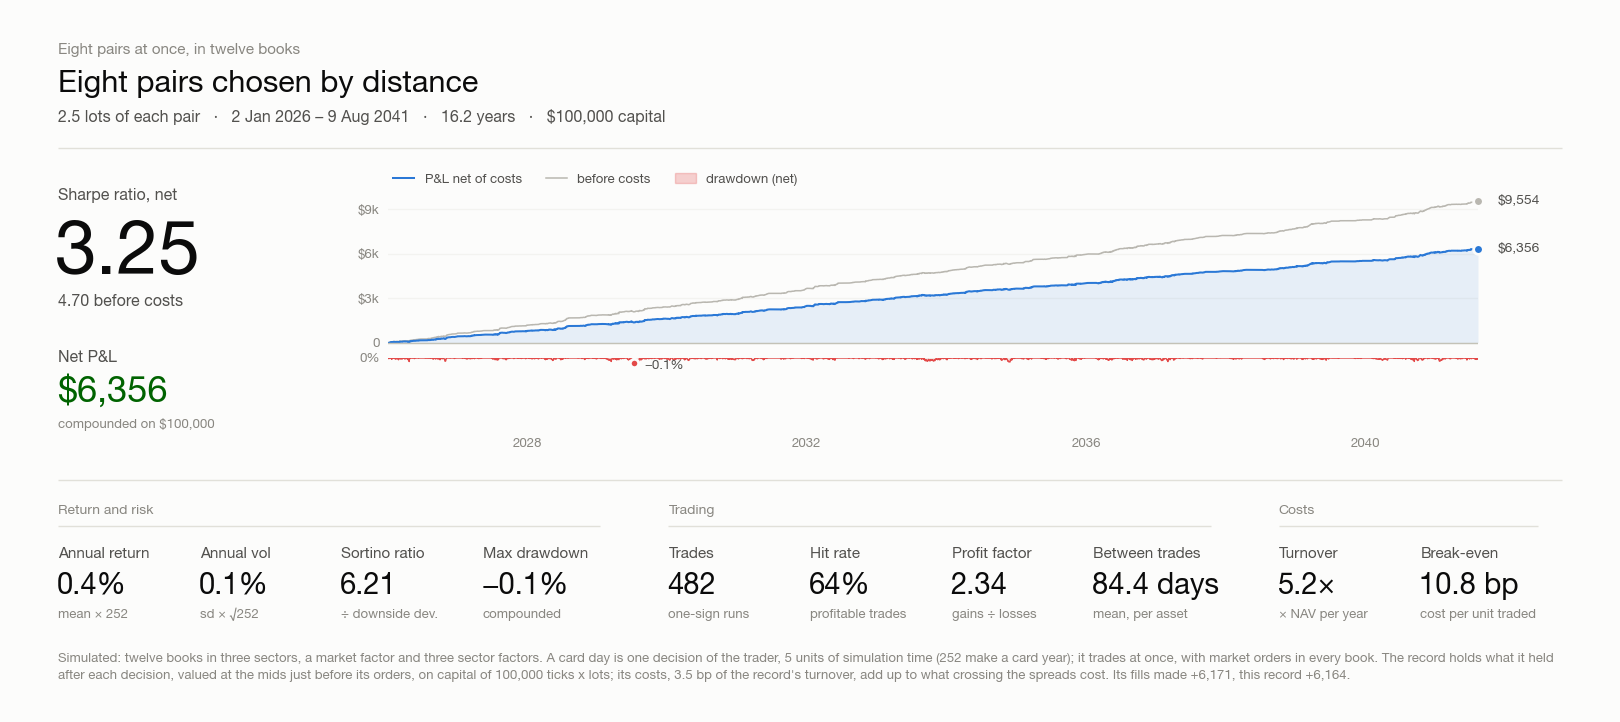

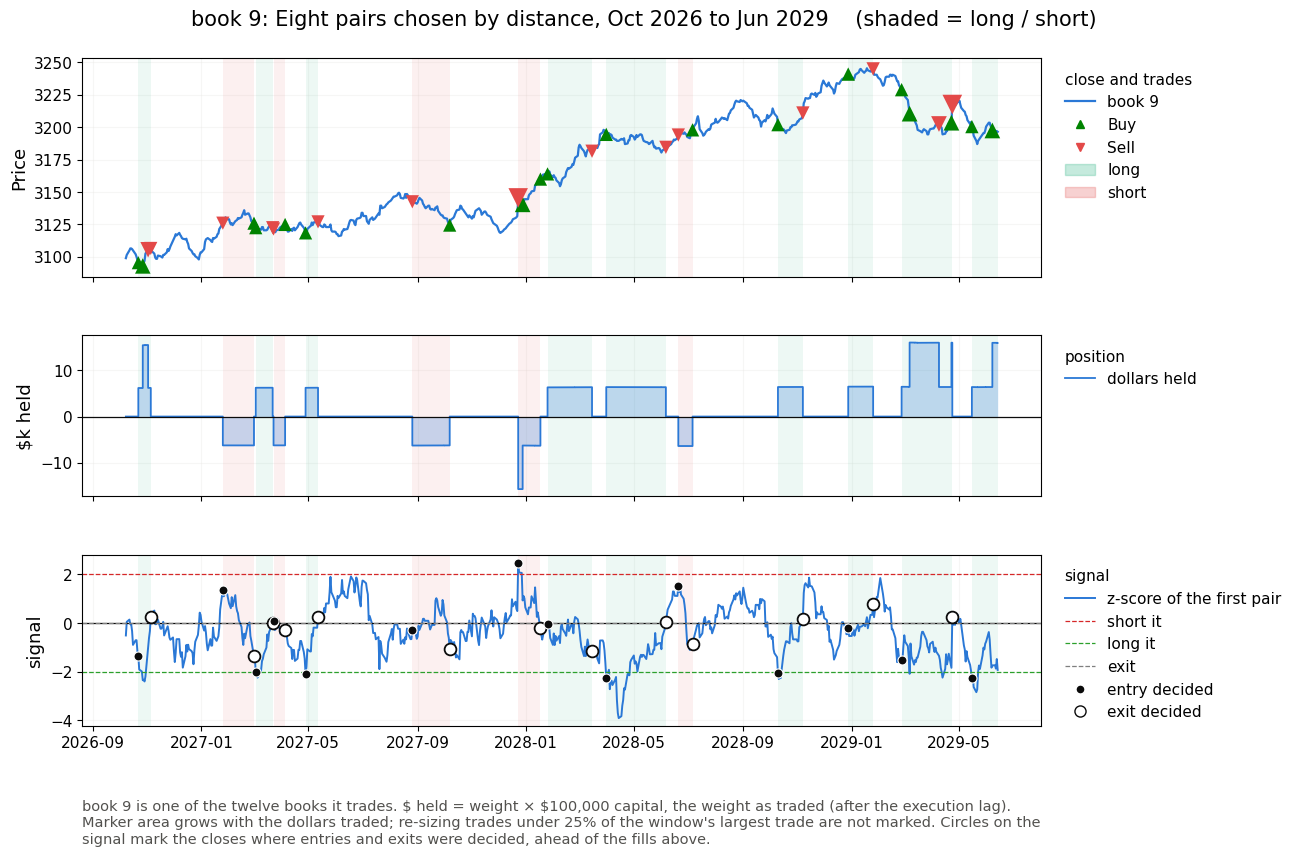

In [10]:
# Ticks x lots: more than the lots a trader here holds on all but a few percent of days. Residuals, copula and
# baskets hold more than it on up to 4% of days, by as much as 1.4 times, and the figures are mildly leveraged then.
CAPITAL = 100_000.0


def record_of(trader, per_unit):
    times, mids, held, signals = zip(*trader.history, strict=True)
    held = np.array(held)
    first = max(int(np.argmax(np.abs(held).sum(axis=1) > 0)) - 1, 0)
    days = pd.bdate_range('2026-01-01', periods=len(times) - first)
    columns = [f'book {i}' for i in range(held.shape[1])]
    prices = pd.DataFrame(np.array(mids)[first:], index=days, columns=columns)
    weights = pd.DataFrame(held[first:] * np.array(mids)[first:] / CAPITAL, index=days, columns=columns)
    returns = prices.pct_change().fillna(0.0)
    turnover = Backtest(weights, returns, cost_bp=0.0).turnover.sum() * CAPITAL
    cost_bp = trader.spread_paid / turnover * 1e4
    return Backtest(weights, returns, cost_bp=cost_bp), prices, weights, signals[first:], days, cost_bp


def card(
    trader,
    fills,
    strategy,
    detail,
    title,
    setting,
    signal_label,
    levels,
    relation,
    book,
    per_unit=5,
    start=200,
    end=900,
):
    bt, prices, weights, signals, days, cost_bp = record_of(trader, per_unit)
    note = (
        f"Simulated: {setting}. A card day is one decision of the trader, {per_unit} unit"
        f"{'' if per_unit == 1 else 's'} of simulation time (252 make a card year); it trades at once, with market "
        f"orders in every book. The record holds what it held after each decision, valued at the mids just before its "
        f"orders, on capital of {CAPITAL:,.0f} ticks x lots; its costs, {cost_bp:.1f} bp of the record's turnover, add "
        f"up to what crossing the spreads cost. Its fills "
        f"made {fills:+,.0f}, this record {bt.net.sum() * CAPITAL:+,.0f}."
    )
    display(scorecard(bt, strategy, detail=detail, capital=CAPITAL, title=title, footnote=note))
    name = f'book {book}'
    signal = pd.Series([np.nan if s is None or len(s) <= relation else s[relation] for s in signals], index=days)
    held = weights[name]
    change = held.ne(0).astype(int).diff().fillna(0)
    signal_chart(
        name,
        prices[name],
        held,
        signal,
        capital=CAPITAL,
        strategy=strategy,
        signal_label=signal_label,
        levels=levels,
        entries=list(days[change > 0]),
        exits=list(days[change < 0]),
        start=days[start],
        end=days[end],
        asset_name='one of the twelve books it trades',
    )
    plt.show()
    return fills, bt.net.sum() * CAPITAL


def recorded(make, loadings=SECTORS):
    trader = make()
    trader.record = True
    market = BookMarket(FactorValues(loadings), seed=SEEDS[0], traders=(trader,))
    while market.time < BURN + SPAN:
        market.step()
    return trader, trader.value(market.marks())


CARDS = {
    'pairs': KINDS['pairs by distance, 8'],
    'copula': KINDS['copula pairs, 8'],
    'baskets': KINDS['baskets of 4 books, 4'],
    'johansen': KINDS['Johansen on all 12, 4'],
    'residuals': KINDS[BEST_RULE],
}
done = dict(zip(CARDS, Parallel(n_jobs=-1)(delayed(recorded)(make) for make in CARDS.values()), strict=True))
SETTING = 'twelve books in three sectors, a market factor and three sector factors'
Z_LEVELS = [(Z['entry'], 'C3', 'short it'), (-Z['entry'], 'C2', 'long it'), (0.0, 'C7', 'exit')]
agreement = {}


def largest_book(trader, relation=0):
    return int(np.argmax(np.abs(trader.weights[relation])))


trader, fills = done['pairs']
agreement['pairs'] = card(
    trader,
    fills,
    'Eight pairs chosen by distance',
    '2.5 lots of each pair',
    'Eight pairs at once, in twelve books',
    SETTING,
    'z-score of the first pair',
    Z_LEVELS,
    0,
    largest_book(trader),
)

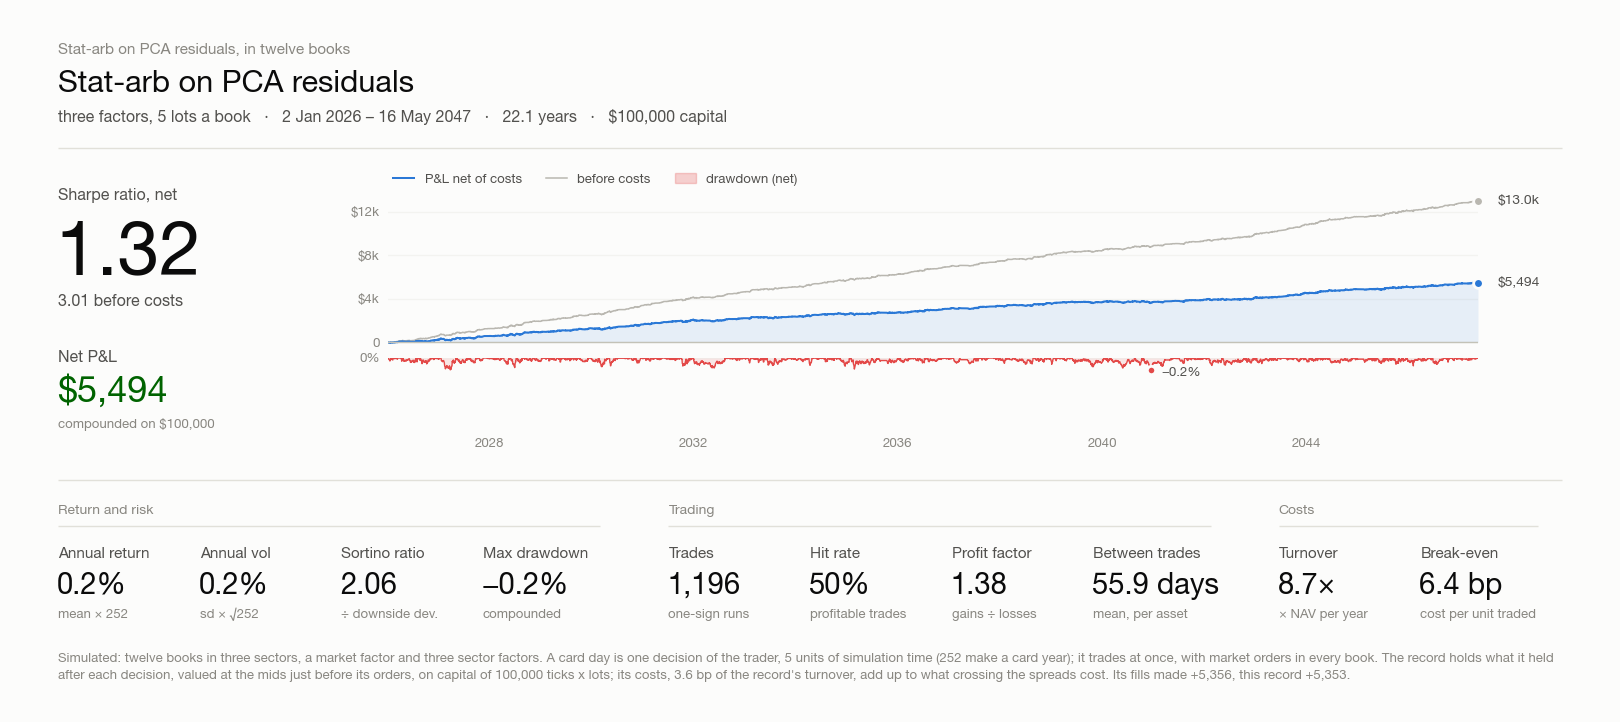

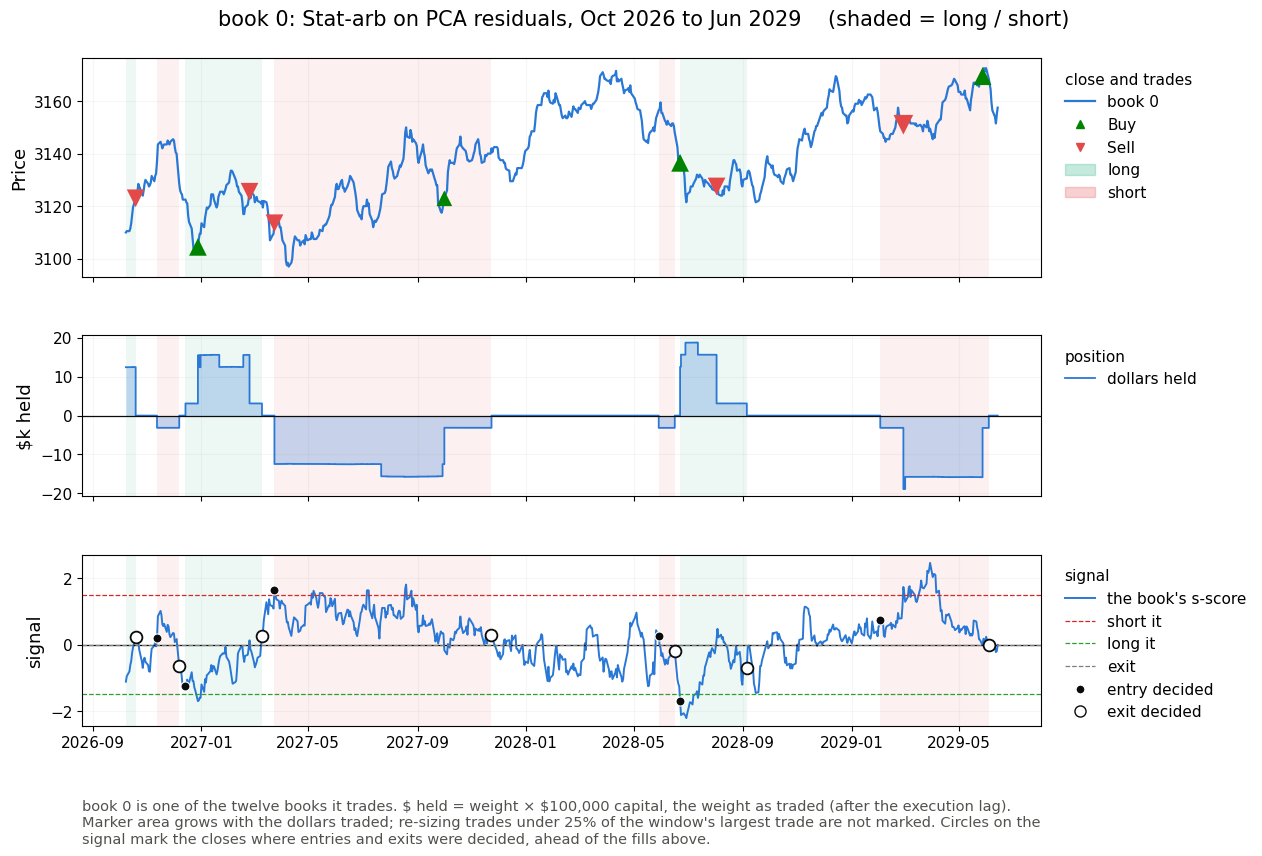

In [11]:
trader, fills = done['residuals']
agreement['residuals'] = card(
    trader,
    fills,
    'Stat-arb on PCA residuals',
    'three factors, 5 lots a book',
    'Stat-arb on PCA residuals, in twelve books',
    SETTING,
    "the book's s-score",
    [(RESIDUAL_BEST['open_at'], 'C3', 'short it'), (-RESIDUAL_BEST['open_at'], 'C2', 'long it'), (0.0, 'C7', 'exit')],
    0,
    0,
)

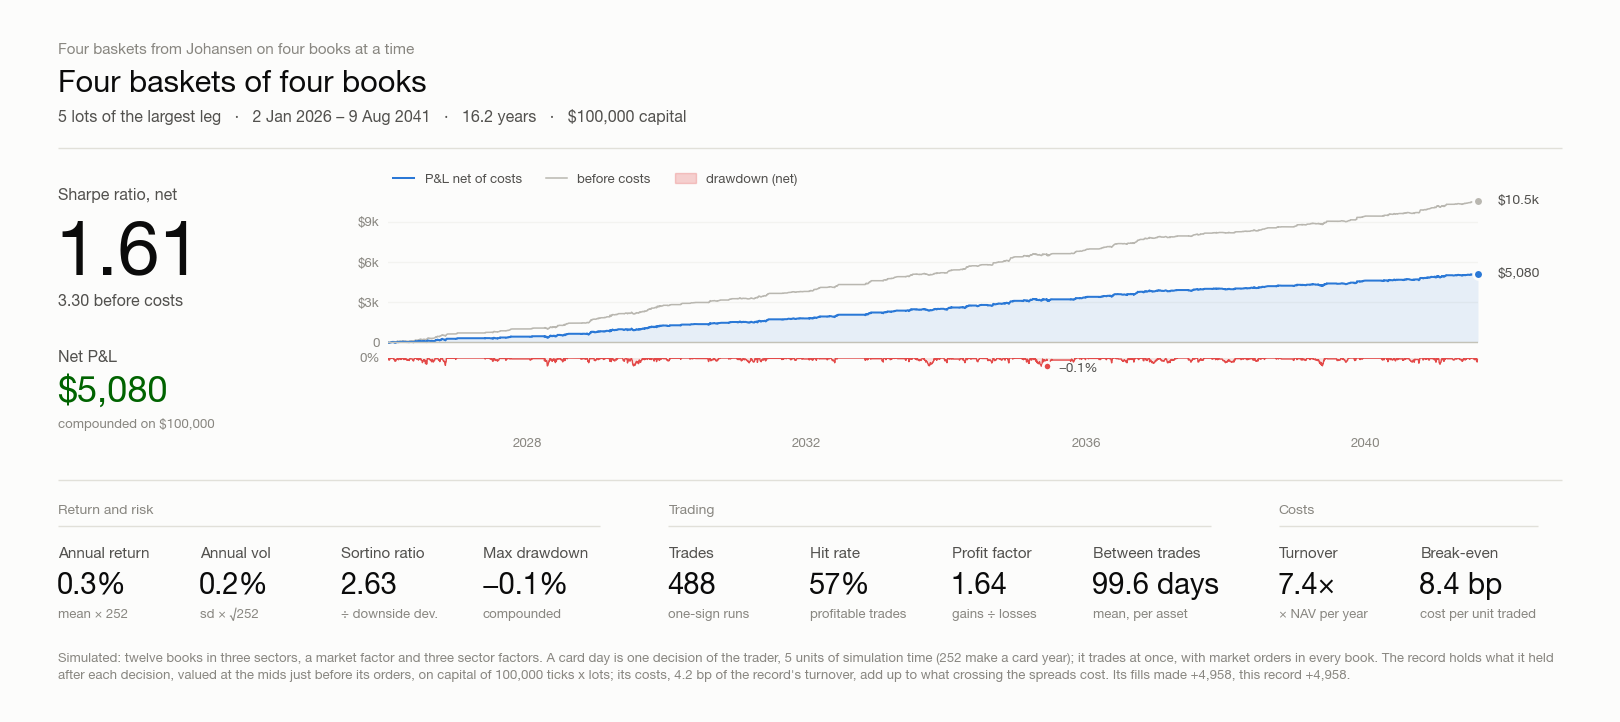

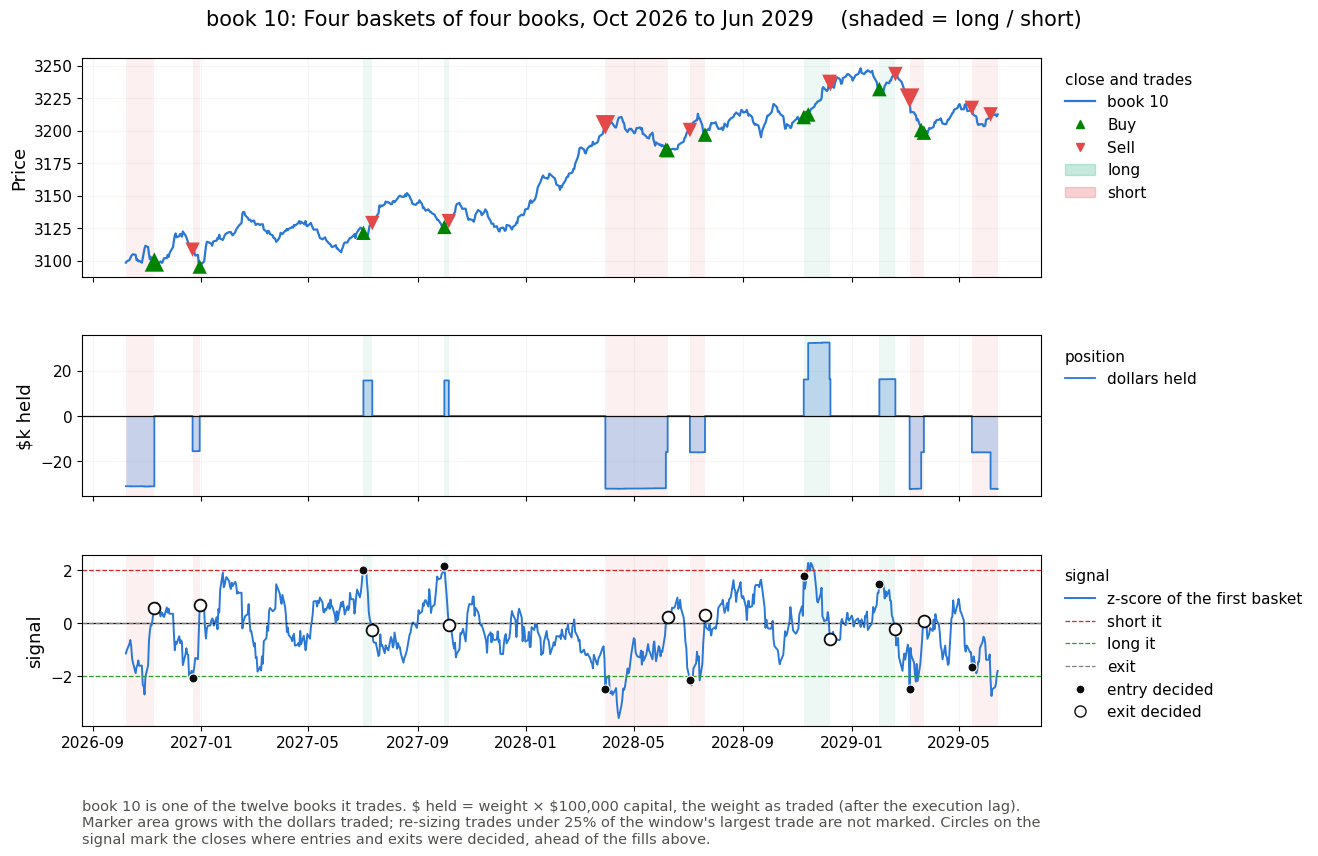

In [12]:
trader, fills = done['baskets']
agreement['baskets'] = card(
    trader,
    fills,
    'Four baskets of four books',
    '5 lots of the largest leg',
    'Four baskets from Johansen on four books at a time',
    SETTING,
    'z-score of the first basket',
    Z_LEVELS,
    0,
    largest_book(trader),
)

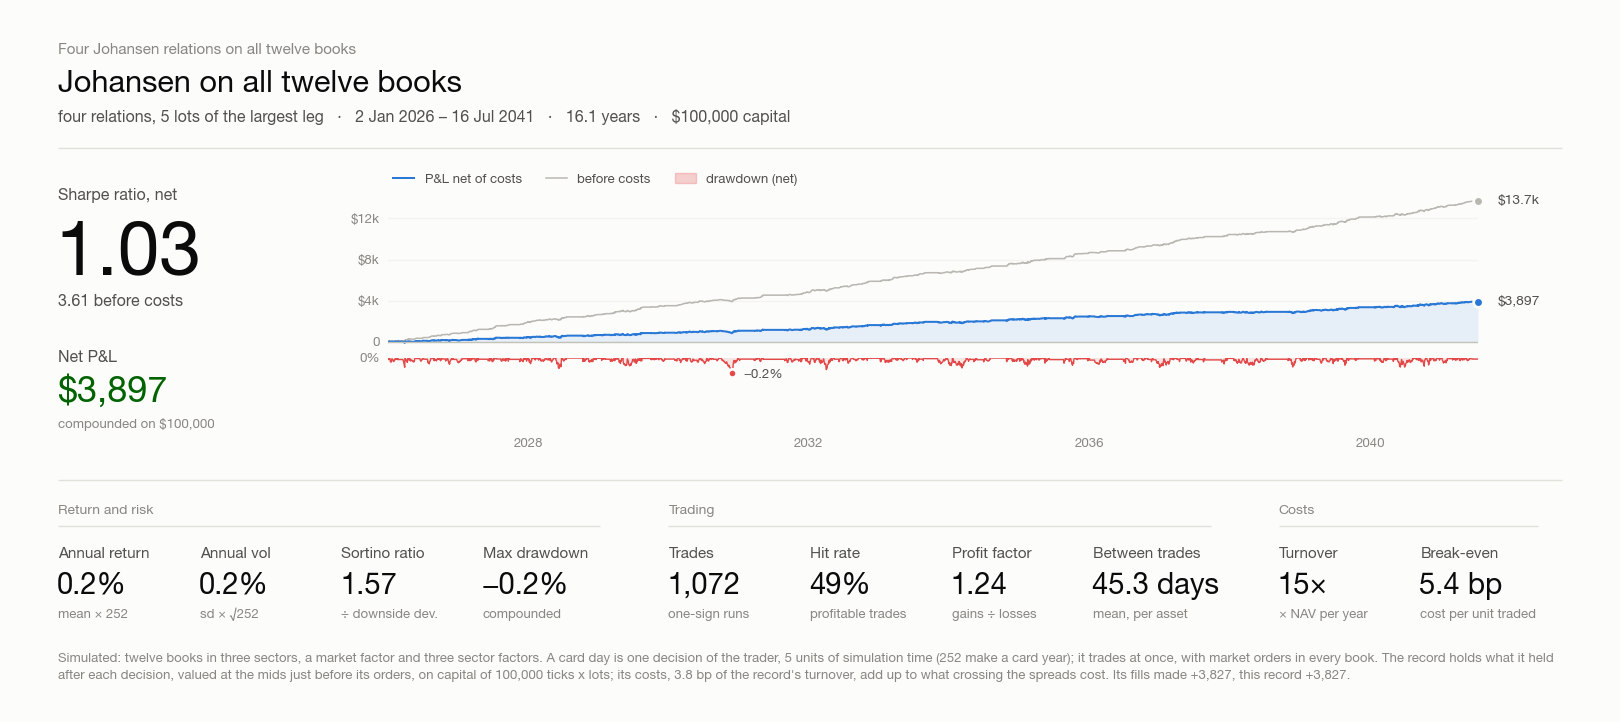

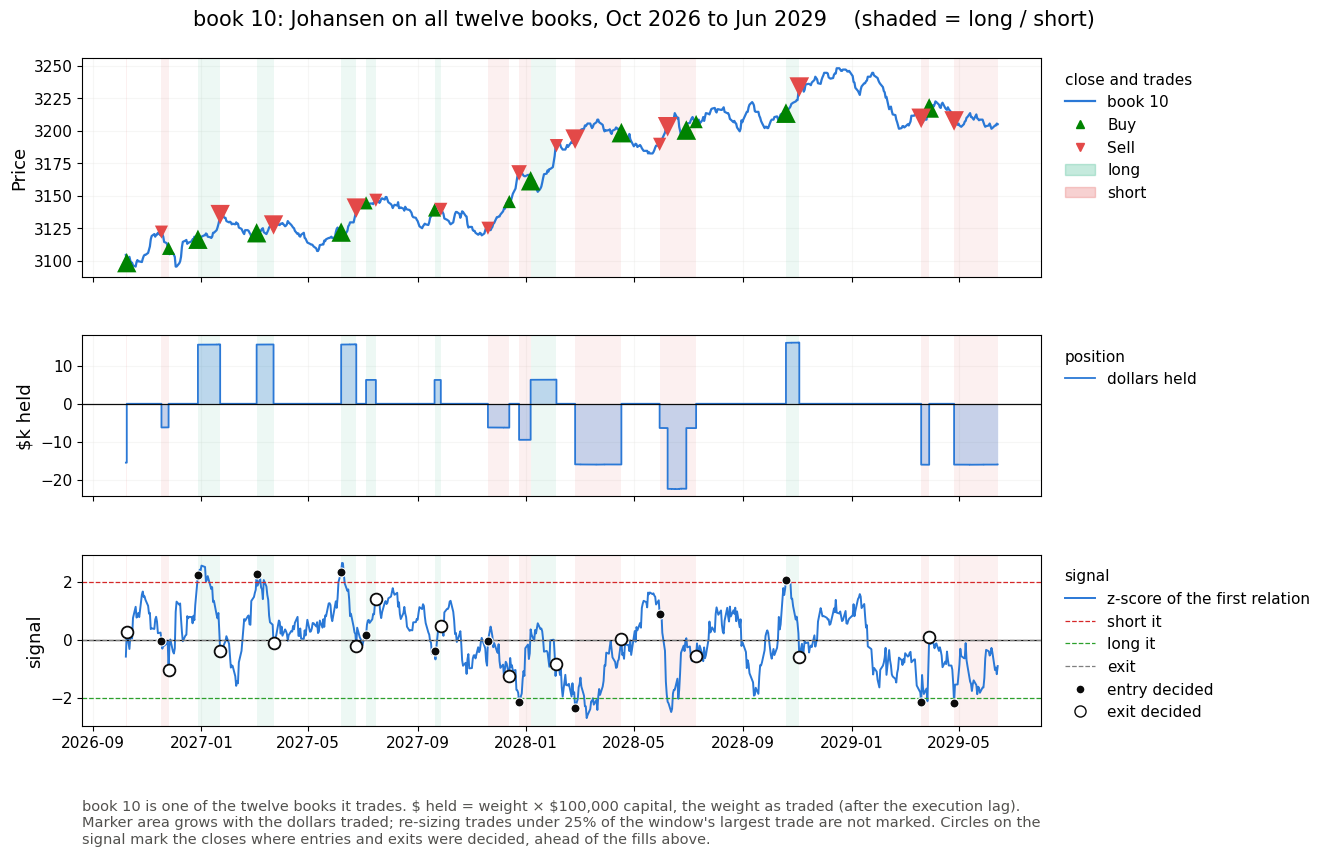

In [13]:
trader, fills = done['johansen']
agreement['johansen'] = card(
    trader,
    fills,
    'Johansen on all twelve books',
    'four relations, 5 lots of the largest leg',
    'Four Johansen relations on all twelve books',
    SETTING,
    'z-score of the first relation',
    Z_LEVELS,
    0,
    largest_book(trader),
)

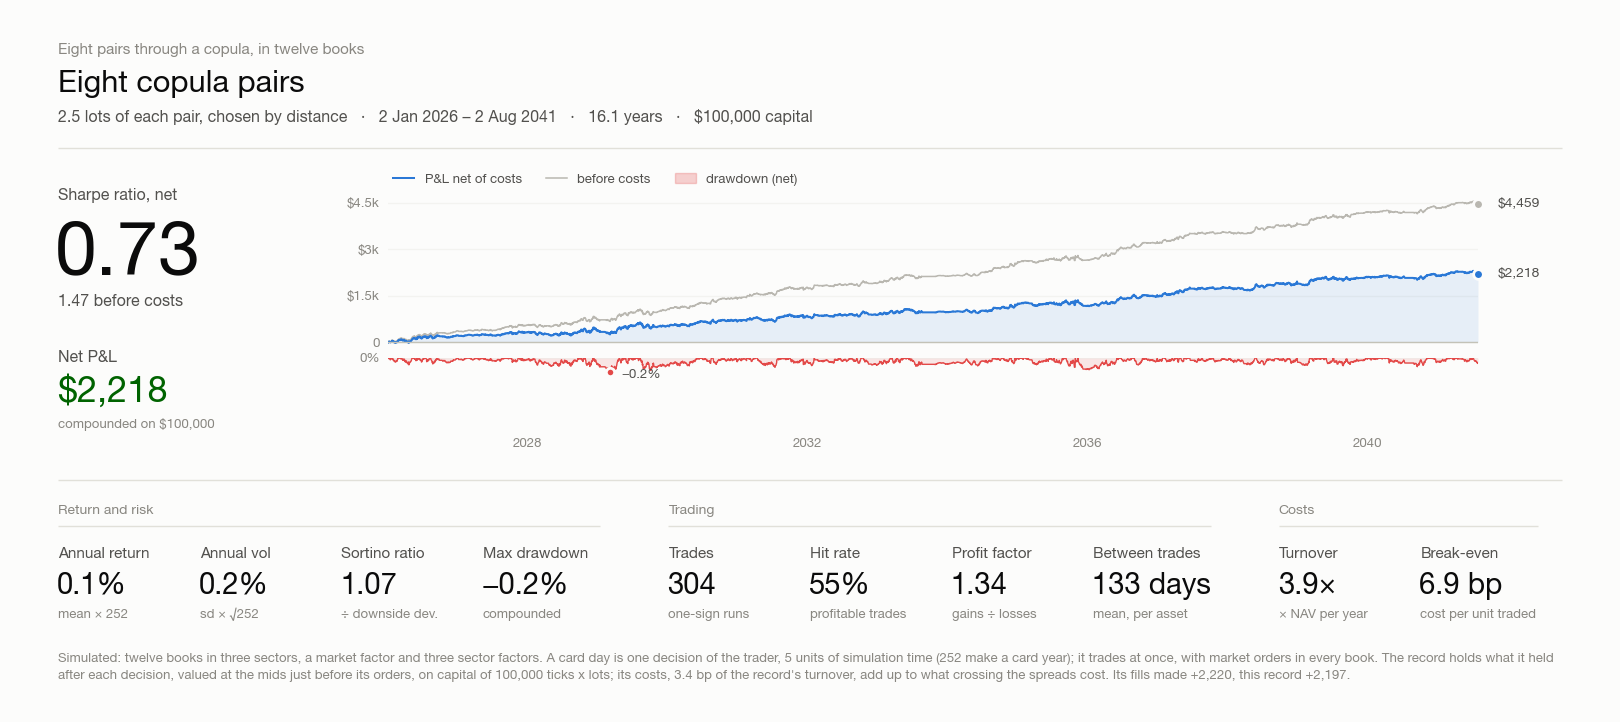

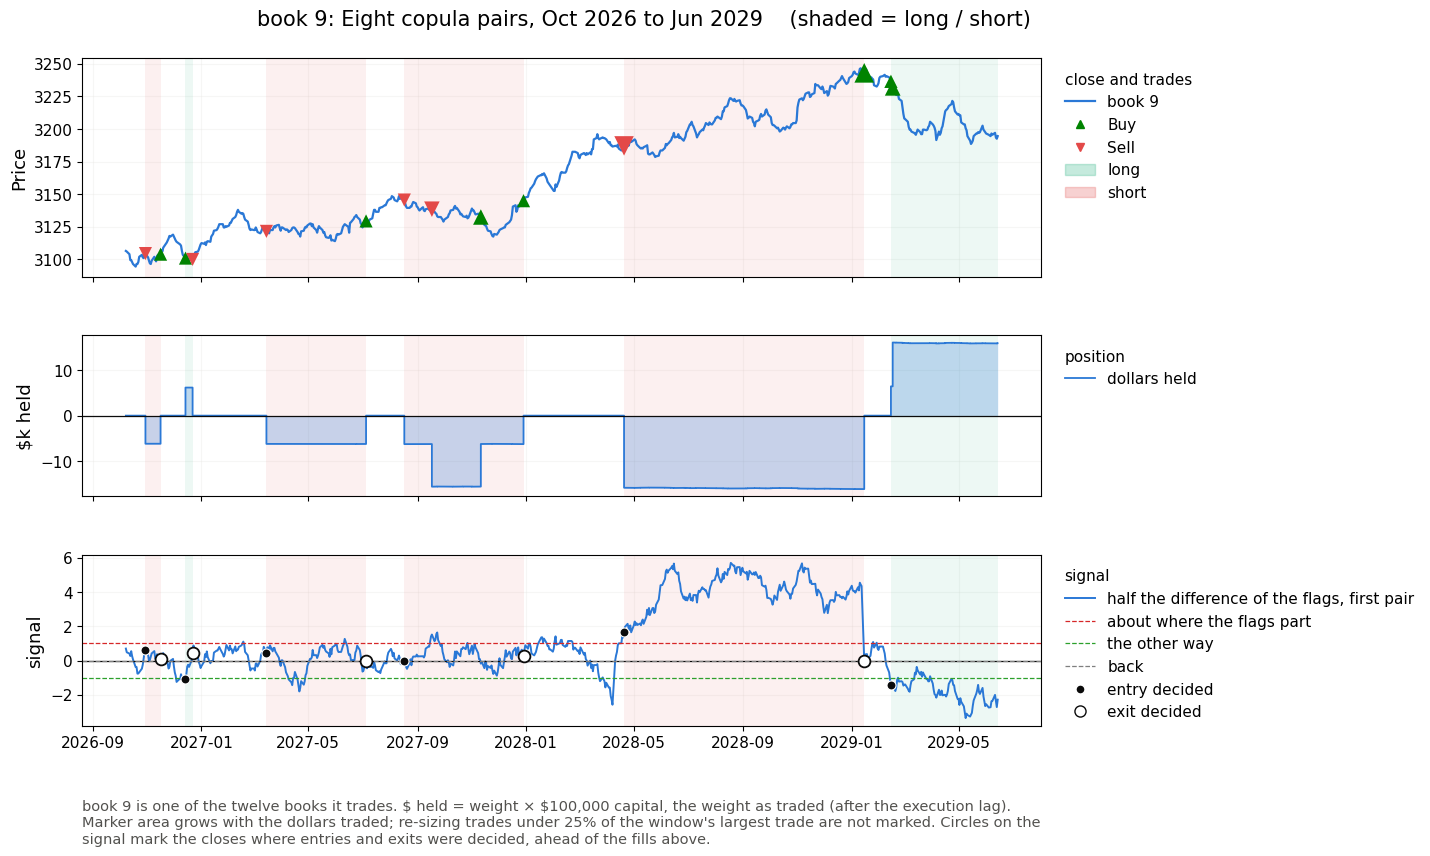

Each card against the fills, within what the run moves after its last decision: {'pairs': '+6,171 and +6,164', 'residuals': '+5,356 and +5,353', 'baskets': '+4,958 and +4,958', 'johansen': '+3,827 and +3,827', 'copula': '+2,220 and +2,197'}


In [14]:
trader, fills = done['copula']
agreement['copula'] = card(
    trader,
    fills,
    'Eight copula pairs',
    '2.5 lots of each pair, chosen by distance',
    'Eight pairs through a copula, in twelve books',
    SETTING,
    'half the difference of the flags, first pair',
    [
        (COPULA['entry'], 'C3', 'about where the flags part'),
        (-COPULA['entry'], 'C2', 'the other way'),
        (0.0, 'C7', 'back'),
    ],
    0,
    largest_book(trader),
)
print(
    'Each card against the fills, within what the run moves after its last decision:',
    {k: f'{a:+,.0f} and {b:+,.0f}' for k, (a, b) in agreement.items()},
)

## 10. Fitting the Settings

The settings so far came from a small grid looked at on seeds 1 to 8. The dashboard's Stat-arb view instead fits a trader's settings on training runs of their own, and compares each with the settings the user started from. Does the panel's fit, from the panel's defaults, help on markets it has not seen, and does it change which kind leads?

The test is what the panel does, at its default lengths:

- **Train.** Each combination of the panel's proposed values, nine for each kind, trades alone in three new markets, over 10,000 units of time after the longest warm-up among them. That is one fit. There are three for each kind in each market, on seeds of their own.
- **Choose**, by three rules: the best by P&L, the panel's default; the best by P&L per unit of risk, its other choice; and the best by P&L only if it beats the starting settings by two standard errors of the difference, which the panel calls *clearly better*. A tie goes as the panel's ranking has it: to the setting that traded fewer lots, and then to the starting one.
- **Test.** The settings chosen, and the starting ones, on the twelve seeds of section 4, over the same 20,000 units after the same warm-up. No fit saw those seeds.

What a fit can find is largely set by where the starting settings sit in the grid, and the grids are the panel's proposals, themselves set on seeds 1 to 8. By P&L on those seeds, over 10,000 units, the start ranks among its nine: pairs 7th in both markets (entry 2 is the highest of the three entries, and pays the least); baskets 3rd in the sectors market and 7th in the mixed (the best entry is 1.5); residuals 4th in sectors and 1st in mixed; copula 1st in both. Where the start was already first there was little gain to find, and a gain near zero there says that, not that fitting hurts. The starts of pairs (by distance), residuals and copula are section 4's traders, which the results cell checks. The baskets are of three books, the panel's default, where section 4's are of four, so their starting figures, and the margin by which a kind leads before fitting, are not section 4's, though the leaders are the same: pairs in the sectors market, baskets in the mixed.

In [15]:
def panel_pairs(window, entry):
    return RelationTrader(
        choose=partial(pairs_by_distance, count=8), formation=FORMATION, window=window, entry=entry, size=2.5,
        interval=EVERY,
    )


def panel_baskets(window, entry):
    return RelationTrader(
        choose=partial(best_baskets, count=4, legs=3, every=1), formation=FORMATION, window=window, entry=entry,
        size=5.0, interval=EVERY,
    )


def panel_residuals(window, open_at):
    return ResidualTrader(
        factors=3, pca_window=500, window=window, open_at=open_at, close_long=0.0, close_short=0.0, size=5.0,
        interval=EVERY,
    )


def panel_copula(entry, trading):
    return CopulaPortfolio(pairs=8, window=FORMATION, trading=trading, entry=entry, size=2.5, interval=EVERY)


# What the panel proposes for each kind: how to make one, the values it tries, and where it starts from. The settings
# are in the panel's order, which is the order its combinations are tried in, and so how a tie breaks.
FIT_KINDS = {
    'pairs': (panel_pairs, dict(window=(200, 400, 800), entry=(1.0, 1.5, 2.0)), dict(window=400, entry=2.0)),
    'baskets': (panel_baskets, dict(window=(200, 400, 800), entry=(1.0, 1.5, 2.0)), dict(window=400, entry=2.0)),
    'residuals': (
        panel_residuals, dict(window=(240, 400, 500), open_at=(1.0, 1.5, 2.0)), dict(window=400, open_at=1.5)
    ),
    'copula': (panel_copula, dict(trading=(100, 200, 400), entry=(0.5, 1.0, 2.0)), dict(trading=200, entry=1.0)),
}
FITS, RUNS, TRAIN_SPAN = 3, 3, 10_000.0
CLEARLY = 2.0  # standard errors of the difference from the start that a setting must beat it by


def candidates_of(kind):
    grid = FIT_KINDS[kind][1]
    return [dict(zip(grid, combination, strict=True)) for combination in itertools.product(*grid.values())]


def setting(values):
    return ', '.join(f'{name.replace("_", " ")} {value:g}' for name, value in values.items())


def make_of(kind, values):
    return partial(FIT_KINDS[kind][0], **values)


START = {kind: setting(values) for kind, (_, _, values) in FIT_KINDS.items()}
LABELS = {kind: {setting(values): values for values in candidates_of(kind)} for kind in FIT_KINDS}
# A training run's burn is the longest warm-up among the kind's candidates, as the panel's plan makes it.
TRAIN_BURN = {
    kind: max(make_of(kind, values)().warm_up for values in [FIT_KINDS[kind][2], *candidates_of(kind)])
    for kind in FIT_KINDS
}


def trained(market, kind, values, fit, run):
    seed = 200_000 + 1_000 * fit + run  # the same for every candidate of a fit, and for every kind and market
    got = scored(make_of(kind, values), MARKETS[market], seed, TRAIN_BURN[kind], TRAIN_SPAN)
    return {
        'market': market,
        'kind': kind,
        'setting': setting(values),
        'fit': fit,
        'run': run,
        'pnl': got['pnl'],
        'risk_adjusted': got['risk_adjusted'],
        'lots': got['lots'],
    }


training = pd.DataFrame(
    Parallel(n_jobs=-1)(
        delayed(trained)(market, kind, values, fit, run)
        for market in MARKETS
        for kind in FIT_KINDS
        for values in candidates_of(kind)
        for fit in range(FITS)
        for run in range(RUNS)
    )
)


def choose(group, yours):
    # What the three rules pick from one fit's runs, each setting scored by its mean over them. A tie goes as in
    # app.training.rank_candidates: to the setting that traded fewer lots, then to the start, then the first tried.
    means = group.groupby('setting', sort=False)[['pnl', 'risk_adjusted', 'lots']].mean()

    def best(score):
        return min(means.index, key=lambda label: (-means.loc[label, score], means.loc[label, 'lots'], label != yours))

    by_pnl, by_risk = best('pnl'), best('risk_adjusted')
    pnl = group.pivot(index='run', columns='setting', values='pnl')
    gap = pnl[by_pnl] - pnl[yours]  # run by run, on the same seeds
    clearly = by_pnl != yours and gap.mean() > CLEARLY * gap.std(ddof=1) / math.sqrt(len(gap))
    return {'yours': yours, 'by_pnl': by_pnl, 'by_risk': by_risk, 'guarded': by_pnl if clearly else yours}


fit_choices = pd.DataFrame(
    [
        {'market': market, 'kind': kind, 'fit': fit, **choose(group, START[kind])}
        for (market, kind, fit), group in training.groupby(['market', 'kind', 'fit'], sort=False)
    ]
)


In [16]:
def tested(market, kind, label, seed):
    got = scored(make_of(kind, LABELS[kind][label]), MARKETS[market], seed, BURN, SPAN)
    return {
        'market': market,
        'kind': kind,
        'setting': label,
        'seed': seed,
        **{key: got[key] for key in ('pnl', 'risk_adjusted', 'costs', 'lots', 'exposure')},
    }


# Every setting that any rule chose, or that a fit started from, once for each market and kind.
wanted = list(
    dict.fromkeys(
        (row.market, row.kind, label)
        for row in fit_choices.itertuples()
        for label in (row.yours, row.by_pnl, row.by_risk, row.guarded)
    )
)
tests = pd.DataFrame(
    Parallel(n_jobs=-1)(
        delayed(tested)(market, kind, label, seed) for market, kind, label in wanted for seed in SEEDS
    )
)
print(f'{len(training)} training runs and {len(tests)} test runs, of {len(wanted)} settings in all.')

648 training runs and 360 test runs, of 30 settings in all.


In [17]:
RULES = ('yours', 'by_pnl', 'by_risk', 'guarded')  # the start, and the three rules
pnl_on = tests.pivot(index=['market', 'kind', 'setting'], columns='seed', values='pnl')  # settings by test seeds
risk_on = tests.pivot(index=['market', 'kind', 'setting'], columns='seed', values='risk_adjusted')
lots_on = tests.pivot(index=['market', 'kind', 'setting'], columns='seed', values='lots')
exposure_on = tests.pivot(index=['market', 'kind', 'setting'], columns='seed', values='exposure')


def se(x):
    return x.std() / math.sqrt(len(x))


def over_fits(on, market, kind, labels):
    # For each test seed, the mean over the fits of the score of the setting each chose.
    return pd.concat([on.loc[(market, kind, label)] for label in labels], axis=1).mean(axis=1)


def chosen_in(market, kind):
    return fit_choices[(fit_choices.market == market) & (fit_choices.kind == kind)]


def beats_start(market, kind, label):
    # Whether a setting did better than the start on the test seeds by two standard errors of the difference there,
    # seed by seed. The start does not beat itself.
    gap = pnl_on.loc[(market, kind, label)] - pnl_on.loc[(market, kind, START[kind])]
    return bool(gap.mean() > CLEARLY * se(gap))


outcomes, counts = [], []
for market in MARKETS:
    for kind in FIT_KINDS:
        chosen = chosen_in(market, kind)
        before = over_fits(pnl_on, market, kind, chosen.yours)
        for rule in RULES:
            pnl = over_fits(pnl_on, market, kind, chosen[rule])
            risk = over_fits(risk_on, market, kind, chosen[rule])
            outcomes.append(
                {
                    'market': market,
                    'kind': kind,
                    'rule': rule,
                    'pnl': pnl.mean(),
                    'se': se(pnl),
                    'gain': (pnl - before).mean(),
                    'gain_se': se(pnl - before),
                    'risk': risk.mean(),
                    'risk_se': se(risk),
                    'lots': over_fits(lots_on, market, kind, chosen[rule]).mean(),
                    'exposure': over_fits(exposure_on, market, kind, chosen[rule]).mean(),
                }
            )
        flagged = chosen.guarded != chosen.yours
        counts.append(
            {
                'market': market,
                'kind': kind,
                'differ': int((chosen.by_pnl != chosen.yours).sum()),
                'beat': sum(beats_start(market, kind, label) for label in chosen.by_pnl),
                'clear': int(flagged.sum()),
                'right': sum(beats_start(market, kind, label) for label in chosen.guarded[flagged]),
            }
        )
outcomes = pd.DataFrame(outcomes).set_index(['market', 'kind', 'rule'])
counts = pd.DataFrame(counts).set_index(['market', 'kind'])

# One row for each market and kind: the start, then each rule's choice, as the mean over the fits.
wide, held = {}, {}
for rule in RULES:
    part = outcomes.xs(rule, level='rule')
    if rule == 'yours':
        start = part
        wide |= {'start': part.pnl, 'start se': part.se, 'start risk': part.risk}
        held |= {'start lots': part.lots, 'start exposure': part.exposure}
    else:
        wide |= {rule: part.pnl, f'{rule} gain': part.gain, f'{rule} se': part.gain_se, f'{rule} risk': part.risk}
        held |= {f'{rule} lots': part.lots / start.lots.replace(0, np.nan), f'{rule} exposure': part.exposure}
table = pd.DataFrame(wide).join(counts)
print(table.round({column: 3 if column.endswith(' risk') else 0 for column in table.columns}).to_string())
print(
    f'\nse of a gain: across the {len(SEEDS)} test seeds, of the mean over the {FITS} fits of chosen less start. '
    f'differ: fits in which the best by P&L was not the start; beat: of those, it did better on the test seeds, by two '
    f'standard errors of its difference from the start there; clear: fits calling it clearly better; right: of those, '
    f'it did better by the same measure. With {FITS} fits to a row, one row\'s counts say little by themselves.'
)

# What each choice holds: what a gain in P&L costs.
print(
    "\nWhat each choice holds, as the mean over the fits: the lots it traded, as a multiple of the start's (the "
    "start's own in lots), and its exposure to the factors, in lots."
)
print(pd.DataFrame(held).round({column: 0 if column == 'start lots' else 2 for column in held}).to_string())

# The fits pooled, by whether the start left a gain to find: it did not if it was the best of its nine by P&L on seeds 1
# to 8 (see the start of this section).
STARTED_BEST = {('mixed', 'residuals'), ('sectors', 'copula'), ('mixed', 'copula')}
BEST, NOT_BEST = 'the start was the best of its grid', 'the start was not the best of its grid'
pooled = counts.assign(fits=FITS).groupby([BEST if key in STARTED_BEST else NOT_BEST for key in counts.index]).sum()
pooled = pooled[['fits', 'differ', 'beat', 'clear', 'right']]
print('\nThe fits pooled, by whether the start was the best of its grid on seeds 1 to 8:')
print(pooled.to_string())


def leaders(means, errors):
    # For each row, the kind ahead, by how much over the runner-up, and the se of that margin. The kinds' runs are not
    # paired, so it is the root of the sum of their squares. A kind leads only if its margin is over two of them.
    rows = []
    for mean, error in zip(means.to_numpy(), errors.to_numpy(), strict=True):
        first, second = np.argsort(-mean)[:2]
        margin, margin_se = mean[first] - mean[second], math.hypot(error[first], error[second])
        rows.append(
            {
                'ahead': means.columns[first],
                'by': margin,
                'se of by': margin_se,
                'leads': means.columns[first] if margin > CLEARLY * margin_se else 'level',
            }
        )
    return pd.DataFrame(rows, index=means.index)


# The kinds side by side, before and after fitting.
order = [(market, rule) for market in MARKETS for rule in RULES]
for label, column, error, digits in (('P&L', 'pnl', 'se', 0), ('P&L per unit of risk', 'risk', 'risk_se', 3)):
    side = outcomes[column].unstack('kind')[list(FIT_KINDS)].loc[order]
    side = side.join(leaders(side, outcomes[error].unstack('kind')[list(FIT_KINDS)].loc[order]))
    print(f'\n{label}, by kind:')
    print(side.rename(index={'yours': 'start'}, level='rule').round(digits).to_string())
print(
    "ahead: the kind with the most; by, and se of by: its margin over the runner-up, and that margin's se; leads: "
    "ahead, or level if the margin is under two se."
)

# The settings the fits chose, by P&L and by risk, to see whether they agree.
print('\nThe settings the fits chose, with how many fits chose each:')
for market in MARKETS:
    for kind in FIT_KINDS:
        chosen = chosen_in(market, kind)
        picked = {}
        for rule in ('by_pnl', 'by_risk'):
            labels = list(chosen[rule])
            picked[rule] = '; '.join(f'{label} x{labels.count(label)}' for label in dict.fromkeys(labels))
        agree = int((chosen.by_pnl == chosen.by_risk).sum())
        print(
            f'{market:8s} {kind:10s} by P&L: {picked["by_pnl"]} | by risk: {picked["by_risk"]} | '
            f'same in {agree} of {FITS}'
        )

# The starting settings of three kinds are section 4's traders, on the same seeds, burn and span: the same P&L.
SAME = {'pairs': 'pairs by distance, 8', 'residuals': BEST_RULE, 'copula': 'copula pairs, 8'}
print('\nThe starting settings against section 4, mean P&L:')
for market in MARKETS:
    for kind, name in SAME.items():
        theirs = kinds_frame[(kinds_frame.market == market) & (kinds_frame.trader == name)].set_index('seed').pnl
        mine = tests[(tests.market == market) & (tests.kind == kind) & (tests.setting == START[kind])]
        mine = mine.set_index('seed').pnl
        print(f'{market:8s} {kind:10s} section 4 {theirs.mean():+,.4f}, here {mine.mean():+,.4f}')
        assert theirs.sort_index().equals(mine.sort_index()), (market, kind)

                    start  start se  start risk  by_pnl  by_pnl gain  by_pnl se  by_pnl risk  by_risk  by_risk gain  by_risk se  by_risk risk  guarded  guarded gain  guarded se  guarded risk  differ  beat  clear  right
market  kind                                                                                                                                                                                                              
sectors pairs      5701.0      77.0       0.070  7868.0       2168.0       84.0        0.062   5634.0         -67.0        97.0         0.071   7868.0        2168.0        84.0         0.062       3     3      3      3
        baskets    5100.0     115.0       0.042  6511.0       1411.0       85.0        0.041   5105.0           6.0       108.0         0.044   6511.0        1411.0        85.0         0.041       3     3      3      3
        residuals  3925.0     139.0       0.032  4629.0        703.0      197.0        0.030   4261.0         336.0       16

In [18]:
rng = np.random.default_rng(12)
TRIALS, CANDIDATES = 200_000, 9
# Fits of nine settings that are truly equal: independent normal scores, the first of them the start's.
scores = rng.standard_normal((TRIALS, CANDIDATES, RUNS))
best = scores.mean(axis=2).argmax(axis=1)
gap = scores[np.arange(TRIALS), best] - scores[:, 0]  # the best's runs less the start's, run by run
rival = scores[:, 1] - scores[:, 0]  # one rival, chosen in advance


def beats(gap):
    return gap.mean(axis=1) > CLEARLY * gap.std(axis=1, ddof=1) / math.sqrt(RUNS)


by_rule = (beats(gap) & (best != 0)).mean()
in_advance = beats(rival).mean()
print(
    f'Of {TRIALS:,} fits of {CANDIDATES} settings that are truly equal, {RUNS} runs each, the rule says clearly '
    f'better in {by_rule:.1%}; for one rival chosen in advance, against the start, {in_advance:.1%}.'
)

Of 200,000 fits of 9 settings that are truly equal, 3 runs each, the rule says clearly better in 27.8%; for one rival chosen in advance, against the start, 9.2%.


**Where the start had room, the fit helps on seeds it never saw.** By P&L, over the same 20,000 units, pairs go from +5,701 to +7,868 in the sectors market (a gain of +2,168, se 84) and from +3,293 to +3,807 in the mixed one (+514, se 81). Baskets go from +5,100 to +6,511 (+1,411, se 85) and from +4,475 to +5,527 (+1,052, se 154). Residuals in the sectors market go from +3,925 to +4,629 (+703, se 197). None of these starts was first of its grid on seeds 1 to 8. Each se is across the test seeds with the settings the fits chose held fixed: it says how sure those settings' gain is on new seeds, not how sure a new fit's would be, since which setting a fit picks is sampled only three times here. Gains and margins in this section are taken from unrounded figures, so one can differ by 1 from the difference of the rounded figures shown.

**Where it had none, there was little to find.** The copula's start was first of its grid in both markets. Its fits there pick settings that do a little worse (-169, se 90, and -119, se 57), a different setting in each of the three fits in the sectors market. Residuals in the mixed market, whose start was also first, gain nothing clear by P&L (+136, se 98), though one of their three fits did find a setting that beat the start, and fitted by *clearly better* they gain +162 (se 37). Notebook 11 found the same of the copula.

**By P&L, the gain is bought with trading.** The fits settle on a lower entry or a longer window, and trade more: pairs 2.7 times the lots in the sectors market and 2.0 in the mixed, baskets 1.7 and 1.6, residuals 1.9 in the sectors market (1.4 in the mixed, where the start was first). They hold a little more of the factors as well. Per unit of risk pairs fall, from 0.070 to 0.062 and from 0.038 to 0.036, and baskets and residuals stay within 0.003 of where they were. So a fit by P&L gives what it is asked for, more P&L, at somewhat worse value per unit of risk for pairs.

**By P&L per unit of risk, a fit asks for something else, and finds less.** The two objectives rarely agree: they choose the same setting in none of the three fits in five of the eight rows. Fitted this way, pairs and baskets in the sectors market keep their P&L (-67, se 97, and +6, se 108) with a little less trading, for a small rise in the figure asked about (0.070 to 0.071, 0.042 to 0.044). Residuals go from 0.032 to 0.036 (+336, se 163) and pairs in the mixed market from 0.038 to 0.043 (+301, se 140). It can also do harm: the copula in the sectors market loses 1,014 (se 131) for a figure below its start's (0.014 against 0.016), since three runs cannot separate figures so close.

**Fitting does not change which kind leads.** In the sectors market pairs lead before and after, by either measure, and fitting by P&L widens their lead, from 601 (se 139) to 1,357 (se 112). So section 4's order was no accident of how its settings were chosen: fitted by P&L the same way as the others, residuals fall further behind. In the mixed market baskets of three lead by P&L, by 1,181 (se 288) before and 1,720 (se 354) after. Per unit of risk they are level with the panel's pairs, which are chosen by distance, except after a fit by P&L.

***Clearly better* was right each time it spoke, on these grids.** It spoke in 13 of the 24 fits, and each of those settings beat the start on the test seeds by two standard errors of the difference. It spoke in 12 of the 15 fits where the start had room, passing up three that were better too, which cost part of the gain (+591 against +703 for residuals in the sectors market, +429 against +514 for pairs in the mixed, +701 against +1,052 for baskets in the mixed). It spoke in 1 of the 9 where the start was first, and kept the copula's start every time, at no cost. Three fits to a row cannot say how often it is right in general, and the grids here hold settings far apart. With nine settings truly equal the same rule says *clearly better* in 27.8% of fits, against 9.2% for one rival chosen in advance, because it tests the best of nine as if it had been chosen beforehand. So it is a useful guard against a fit with nothing to find, not a test at any stated level.

Here is what a fit finds in a backtest's terms, on a seed no fit saw.

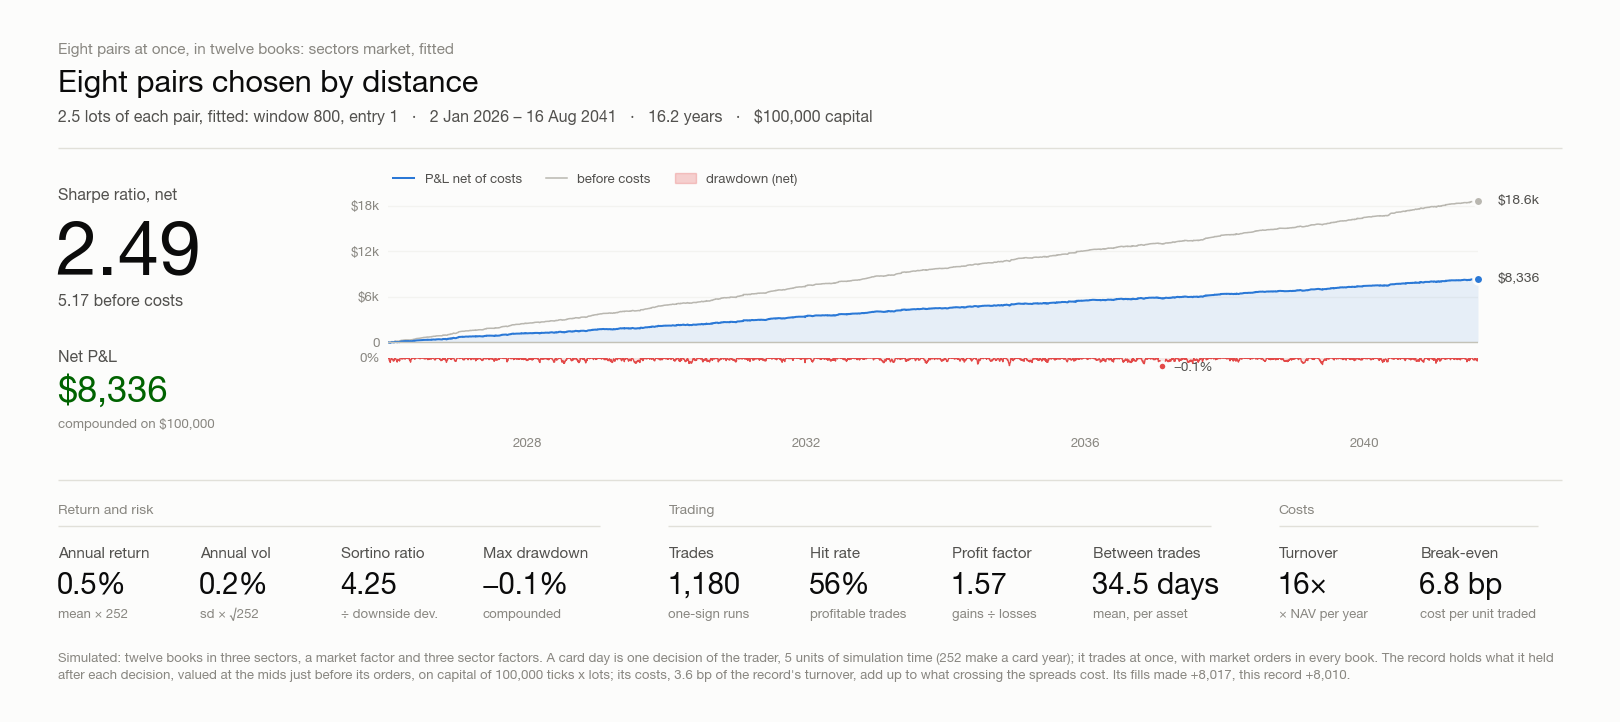

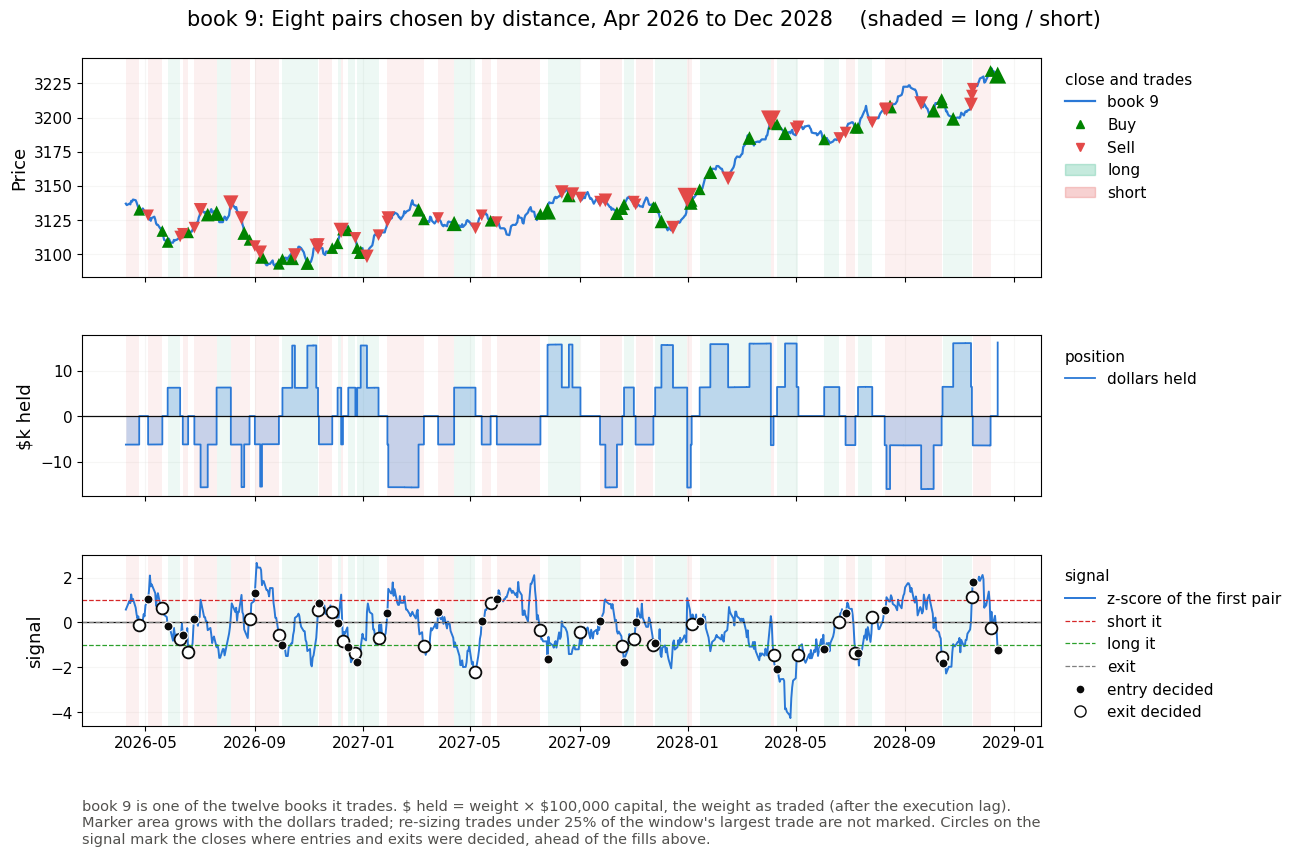

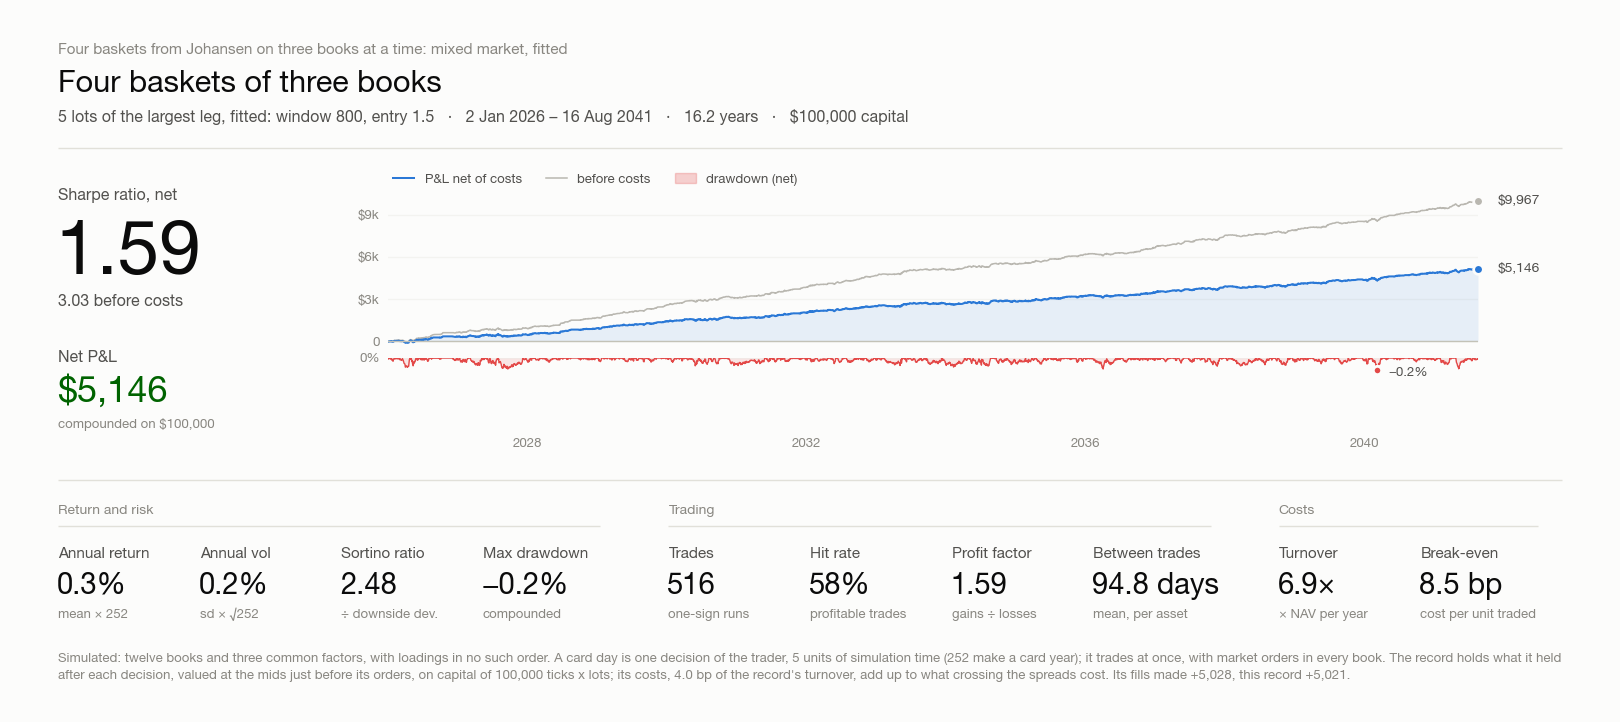

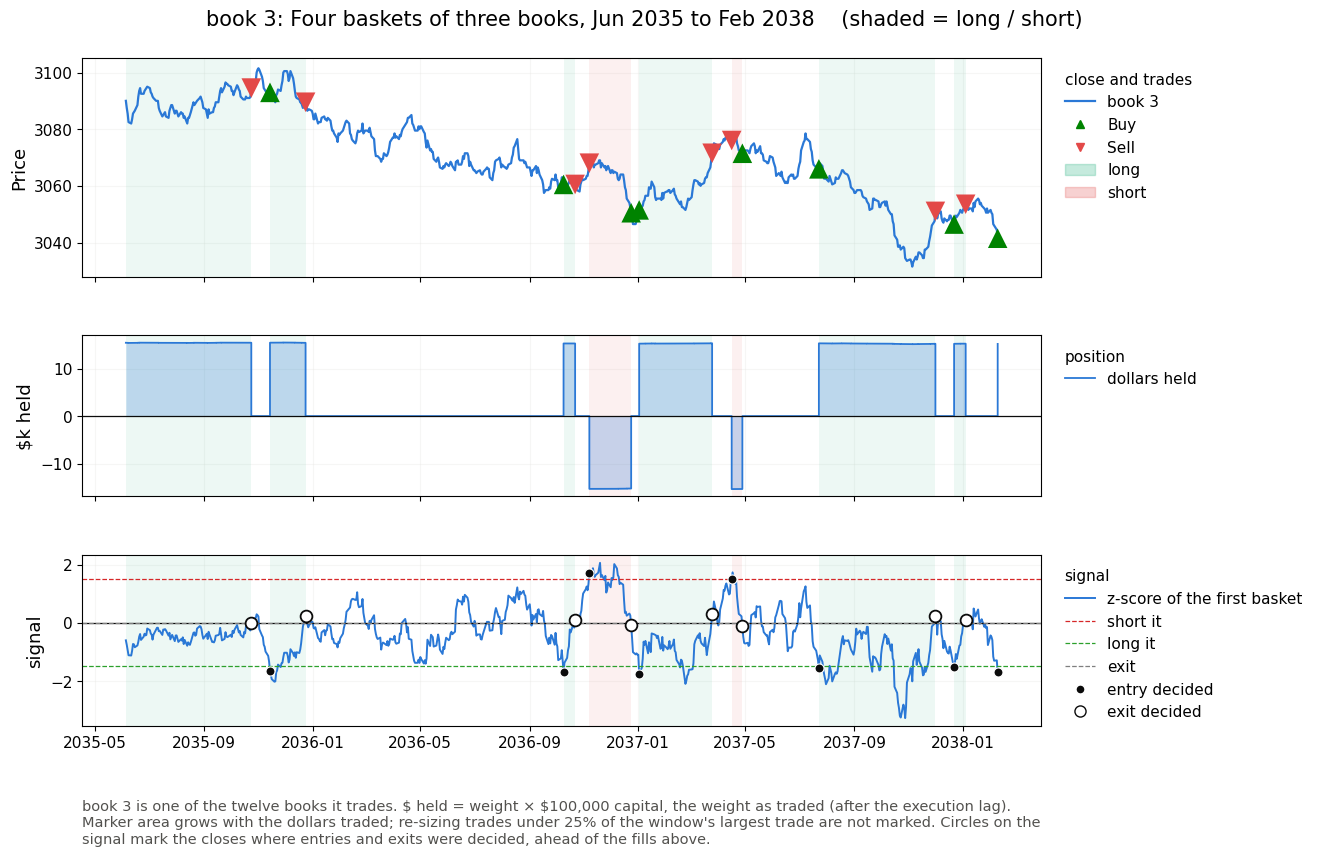

Each card against the fills, within what the run moves after its last decision: {'sectors, pairs': '+8,017 and +8,010', 'mixed, baskets': '+5,028 and +5,021'}
The most each card holds, as a multiple of the capital (above 1 the figure is leveraged): {'sectors, pairs': '1.09, above 1 on 2.2% of days', 'mixed, baskets': '1.29, above 1 on 7.1% of days'}


In [19]:
CARD_FORMS = {
    'pairs': dict(
        strategy='Eight pairs chosen by distance',
        detail='2.5 lots of each pair',
        title='Eight pairs at once, in twelve books',
        signal_label='z-score of the first pair',
        levels=lambda v: [(v['entry'], 'C3', 'short it'), (-v['entry'], 'C2', 'long it'), (0.0, 'C7', 'exit')],
    ),
    'baskets': dict(
        strategy='Four baskets of three books',
        detail='5 lots of the largest leg',
        title='Four baskets from Johansen on three books at a time',
        signal_label='z-score of the first basket',
        levels=lambda v: [(v['entry'], 'C3', 'short it'), (-v['entry'], 'C2', 'long it'), (0.0, 'C7', 'exit')],
    ),
    'residuals': dict(
        strategy='Stat-arb on PCA residuals',
        detail='three factors, 5 lots a book',
        title='Stat-arb on PCA residuals, in twelve books',
        signal_label="the book's s-score",
        levels=lambda v: [(v['open_at'], 'C3', 'short it'), (-v['open_at'], 'C2', 'long it'), (0.0, 'C7', 'exit')],
    ),
    'copula': dict(
        strategy='Eight copula pairs',
        detail='2.5 lots of each pair, chosen by distance',
        title='Eight pairs through a copula, in twelve books',
        signal_label='half the difference of the flags, first pair',
        levels=lambda v: [
            (v['entry'], 'C3', 'about where the flags part'),
            (-v['entry'], 'C2', 'the other way'),
            (0.0, 'C7', 'back'),
        ],
    ),
}
MARKET_LINES = {
    'sectors': SETTING,
    'mixed': 'twelve books and three common factors, with loadings in no such order',
}


def most_chosen(market, kind, rule='by_pnl'):
    labels = list(chosen_in(market, kind)[rule])
    return max(dict.fromkeys(labels), key=labels.count)  # the first of those chosen most often


def trading_days(weights, book, length=700):
    # The card days, as card() counts them, of the stretch of `length` decisions in which the book trades most.
    moves = weights[f'book {book}'].ne(0).astype(int).diff().fillna(0).abs().cumsum().to_numpy()
    if len(moves) <= length:
        return 0, len(moves) - 1
    start = int(np.argmax(moves[length:] - moves[:-length]))
    return start, start + length


# The by-P&L setting most fits chose for pairs in the sectors market, and for whichever kind makes the most in the
# mixed market once fitted by P&L.
leader = outcomes.xs(('mixed', 'by_pnl'), level=('market', 'rule')).pnl.idxmax()
FITTED = {
    (market, kind): LABELS[kind][most_chosen(market, kind)]
    for market, kind in (('sectors', 'pairs'), ('mixed', leader))
}
fitted_done = Parallel(n_jobs=-1)(
    delayed(recorded)(make_of(kind, values), MARKETS[market]['loadings']) for (market, kind), values in FITTED.items()
)
fitted_agreement, peaks = {}, {}
for ((market, kind), values), (trader, fills) in zip(FITTED.items(), fitted_done, strict=True):
    form = CARD_FORMS[kind]
    book = 0 if kind == 'residuals' else largest_book(trader)
    weights = record_of(trader, int(EVERY))[2]
    gross = weights.abs().sum(axis=1)  # what it holds, as a multiple of the capital
    peaks[f'{market}, {kind}'] = f'{gross.max():.2f}, above 1 on {(gross > 1).mean():.1%} of days'
    first_day, last_day = trading_days(weights, book)
    fitted_agreement[f'{market}, {kind}'] = card(
        trader,
        fills,
        form['strategy'],
        f"{form['detail']}, fitted: {setting(values)}",
        f"{form['title']}: {market} market, fitted",
        MARKET_LINES[market],
        form['signal_label'],
        form['levels'](values),
        0,
        book,
        start=first_day,
        end=last_day,
    )
print(
    'Each card against the fills, within what the run moves after its last decision:',
    {k: f'{a:+,.0f} and {b:+,.0f}' for k, (a, b) in fitted_agreement.items()},
)
print('The most each card holds, as a multiple of the capital (above 1 the figure is leveraged):', peaks)


## 11. Conclusions

In [20]:
def row(table, market, trader):
    return table.loc[(market, trader)]


def said(r):
    return f'{r.pnl:+,.0f} (se {r.se:.0f}, {r.positive} seeds positive)'


print(
    f"- The trace test needs long spans: over 2,000 units it finds {ranks['rank over 2,000'].mean():.1f} of the 9 "
    f"relations on "
    f"average, over 10,000 {ranks['rank over 10,000'].mean():.1f}, over 20,000 {ranks['rank over 20,000'].mean():.1f}."
)
near = flags[(flags.market == 'mixed') & (flags.left < 0.3)].flagged.mean()
far = flags[(flags.left > 0.7)].flagged.mean()
print(
    f"- With no pair truly cointegrated, Engle-Granger calls {near:.0%} of the pairs with under 0.3 of the factors "
    f"left "
    f"cointegrated, and {far:.0%} of those with over 0.7, at a nominal 5%."
)
for name in MARKETS:
    print(
        f"- {name}: eight pairs by distance {said(row(kinds, name, 'pairs by distance, 8'))}; eight copula pairs "
        f"{said(row(kinds, name, 'copula pairs, 8'))}; four baskets of four "
        f"{said(row(kinds, name, 'baskets of 4 books, 4'))}; Johansen on all twelve "
        f"{said(row(kinds, name, 'Johansen on all 12, 4'))}; residuals {said(row(kinds, name, BEST_RULE))}, "
        f"and by the published rule {said(row(kinds, name, PAPER_RULE))}."
    )
print(
    f"- Each leg costs: from 2 legs to 12 the before-cost P&L grows {legs_table.before_costs_vs_2.iloc[-1]:.2f} times "
    f"(the square root of 6 is {math.sqrt(6):.2f}), and the costs {legs_table.costs_vs_2.iloc[-1]:.2f} times."
)
first, last = row(breadth, 'sectors', '1 pair of 20 lots'), row(breadth, 'sectors', '8 pairs of 2.5 lots')
print(
    f"- The same 20 lots in one pair make {first.pnl:+,.0f} at {first.cost_a_lot:.2f} ticks a lot, and in eight pairs "
    f"{last.pnl:+,.0f} at {last.cost_a_lot:.2f}; before costs {first.before_costs:+,.0f} and {last.before_costs:+,.0f}."
)
print(
    f"- Netting saved {netting.saved.iloc[0]:.2%} of the lots when deciding every unit, and "
    f"{netting.saved.iloc[-1]:.2%} every 20."
)
print(
    f"- As loadings drift by 0.4, pairs make {said(row(drifts, 'loadings drift by 0.4', 'pairs, 2'))}, and residuals "
    f"{said(row(drifts, 'loadings drift by 0.4', 'residuals'))}."
)

for name in MARKETS:
    parts = []
    for kind in FIT_KINDS:
        before, after = outcomes.loc[(name, kind, 'yours')], outcomes.loc[(name, kind, 'by_pnl')]
        times = after.lots / before.lots if before.lots else float('nan')
        parts.append(
            f"{kind} {before.pnl:+,.0f} to {after.pnl:+,.0f} (gain {after.gain:+,.0f}, se {after.gain_se:.0f}; "
            f"lots {times:.1f} times the start's, exposure {before.exposure:.1f} to {after.exposure:.1f})"
        )
    print(f"- {name}, fitted on training runs, by P&L, against the starting settings: {'; '.join(parts)}.")
for label, part in pooled.iterrows():
    print(
        f"- In {part.fits} fits in which {label}, the best by P&L differed from the start in {part.differ} and beat it "
        f"by two standard errors on the test seeds in {part.beat}; clearly better was called in {part.clear}, and "
        f"rightly, by the same measure, in {part.right}."
    )
print(
    f"- With {CANDIDATES} settings that are truly equal, the rule for clearly better says so in {by_rule:.0%} of fits, "
    f"and for one rival chosen in advance in {in_advance:.0%}."
)

- The trace test needs long spans: over 2,000 units it finds 0.3 of the 9 relations on average, over 10,000 9.0, over 20,000 9.1.
- With no pair truly cointegrated, Engle-Granger calls 91% of the pairs with under 0.3 of the factors left cointegrated, and 9% of those with over 0.7, at a nominal 5%.
- sectors: eight pairs by distance +5,701 (se 77, 12 of 12 seeds positive); eight copula pairs +1,913 (se 111, 12 of 12 seeds positive); four baskets of four +4,924 (se 114, 12 of 12 seeds positive); Johansen on all twelve +3,917 (se 77, 12 of 12 seeds positive); residuals +3,925 (se 139, 12 of 12 seeds positive), and by the published rule -8,976 (se 153, 0 of 12 seeds positive).
- mixed: eight pairs by distance +3,293 (se 262, 12 of 12 seeds positive); eight copula pairs +1,328 (se 163, 12 of 12 seeds positive); four baskets of four +4,695 (se 91, 12 of 12 seeds positive); Johansen on all twelve +3,889 (se 106, 12 of 12 seeds positive); residuals +2,669 (se 114, 12 of 12 seeds positive), and

**Limitations.** Every book here has the same volatility and half-life, so all relations revert at the same speed: Johansen's vectors are then arbitrary within the space of relations, and real ones would differ. The settings come from a small grid, on seeds 1 to 8, and so do the grids section 10's fits search, whose gains depend on where each start sits in them; three fits to a row cannot say how often *clearly better* is right. Each trader is alone, with market orders only, at sizes chosen not to walk the book much, and passive orders could change every comparison that costs decide. Lots are whole, so that small hedges round away. Twelve books are few for stat-arb: Avellaneda and Lee trade about a thousand names once a day, which is where breadth and netting should matter most. "Many pairs" here means pairs side by side: joint dependence among more than two books, through vine copulas (Stübinger, Mangold and Krauss 2018), is not tried. A single table of loadings stands for each market.